# RADIOBLOCKS scenarios A, B and C at 250 MHz: a Gaussian source observed with 6 LBA-type antennas + SKA-Low

This notebook tests a **self-calibration + closure-quantity imaging pipeline** on a simulated low-frequency VLBI observation of a southern-sky **circular Gaussian source**, under three error scenarios (the same definitions as the `ehtim` ionospheric-corruptions hands-on):

| Scenario | Errors | `observe()` settings |
|---|---|---|
| Reference (not a scenario) | none | `add_th_noise=False`, `ampcal=True`, `phasecal=True` |
| **A** | thermal noise only | `add_th_noise=True`, `ampcal=True`, `phasecal=True` |
| **B** | thermal noise + gain errors + generic (`ehtim` random) phase errors | `add_th_noise=True`, `ampcal=False` + `gain_offset`, `gainp`, `phasecal=False` |
| **C** | thermal noise + gain errors + structured ionospheric (dTEC) and delay phase errors | same noise and gains as B, `phasecal=True`, plus the screen of Section 6 |

**Configuration**
* **Array:** six Australian Long Baseline Array (LBA) antennas (Parkes, ATCA, Hobart, Ceduna, Warkworth (30 m) and Katherine) plus **SKA-Low** (Murchison, Western Australia), seven stations in total. The array is called **LBA + SKA-Low** throughout: **SKA-Low is included in every simulation, calibration and image of this notebook** (there is no LBA-only run), and it is by far its most sensitive element.
* **Observing frequency / bandwidth:** 250 MHz / 50 MHz (modelled in 32 channels for the in-band ionospheric decorrelation).
* **Source:** circular Gaussian, 80 mas FWHM, 1 Jy, at RA 5 h, Dec −35°.

> **Important:** the LBA has no receivers at 250 MHz (its lowest band is ~700 MHz at Parkes and 1.3–1.4 GHz at the other antennas; see References), so this is a **hypothetical low-frequency configuration**. Positions and apertures are real; the LBA station sensitivities (SEFD) are **set to ~2000 Jy** (a conservative low-frequency value, see Section 1) and the SKA-Low SEFD is **computed from its collecting area and an assumed system temperature**.

## 0. Setup

In [1]:
import os, time, io, contextlib
import numpy as np
import matplotlib.pyplot as plt
import ehtim as eh
from ehtim.calibrating import self_cal as sc

# ---- Output folder: every figure, visibility file and image is collected here (see Section 11) ----
OUT_DIR = 'results_VLBI'
for sub in ('figures', 'visibilities', 'images', 'tables'):
    os.makedirs(f'{OUT_DIR}/{sub}', exist_ok=True)

def save_fig(fig, name):
    fig.savefig(f'{OUT_DIR}/figures/{name}.png', dpi=150, bbox_inches='tight')


Welcome to eht-imaging! v 1.2.10 



## 1. Array (LBA + SKA-Low), sensitivities (SEFD) and observing parameters

The array is the **LBA + SKA-Low**: six LBA antennas **plus SKA-Low**, which takes part in every simulated observation.

**Station sensitivities.** There are no published SEFDs at 250 MHz for these antennas, because the LBA cannot observe there, and SKA-Low is not an LBA antenna.

* **LBA antennas (PKS, ATCA, HOB, CED, WARK, KAT):** the SEFD is **fixed at ~2000 Jy** at 250 MHz (`sefd_lba_250`, one editable entry per station). This is deliberately higher than a naive extrapolation. The cell still prints that extrapolation for reference: published 1.3 GHz values (Li et al. 2024, Table A1: Parkes 40 Jy, ATCA 57 Jy, Hobart 470 Jy), Ceduna, Warkworth and Katherine scaled from Hobart by collecting area (cross-checked against the published 8.3 GHz and 6.7 GHz values), and everything scaled to 250 MHz with the system-temperature ratio T_sys = T_rx + T_other + T_sky(ν) (sky: 237 K at 150 MHz, spectral index 2.52, Rogers & Bowman 2008; T_rx = 30 K and T_other = 5 K assumed).
* **SKA-Low (`SKAL`)** at the Murchison Radio-astronomy Observatory (≈ 26.70° S, 116.76° E). Its SEFD is computed directly as SEFD = 2 k_B T_sys / A_eff, with the same T_sys model as above. The effective area per station is `ska_n_elem` = 256 dipoles with A_eff ≈ λ²/3 each (the usual estimate at frequencies above the dense-array regime), and `ska_n_tied` stations are assumed to be phased together as a tied array, the same convention used for ATCA. With the default of 512 stations SKA-Low is by far the most sensitive element. Set `ska_n_tied` to a smaller number to model a sub-array (a single station gives ~2200 Jy).

Since `observe()` takes the (u,v) points from the **image** frequency, `nu` is set on the image in Section 2.


In [2]:
nu, bw, n_chan = 250e6, 50e6, 32
tint, tadv, avg_time = 120, 300, 30      # scan length, scan spacing, coherent averaging [s]
obs_hours = 8                            # length of the observing window [h]
elevation_min = 10.0
gain_offset_val, gainp_val = 0.15, 0.10  # gain-error budget of the ehtim hands-on (scenarios B and C)
flux_jy = 1.0                            # source flux at 250 MHz [Jy]
src_fwhm_mas = 80.0                      # FWHM of the circular Gaussian source [mas] (array beam is ~50-80 mas)
beam_weighting = 'uniform'               # dirty-beam weighting that defines the final restoring beam ('uniform' or 'natural')
npix_rec, fov_beams = 64, 10             # reconstruction grid: pixels per side, and FOV in units of the nominal beam
src_ra_h, src_dec_deg = 5.0, -35.0       # southern source, visible from all seven sites for several hours

def llh2xyz(lat, lon, h):
    a = 6378137.0; f = 1/298.257223563; e2 = f*(2-f)
    la, lo = np.radians(lat), np.radians(lon); N = a/np.sqrt(1 - e2*np.sin(la)**2)
    return (N+h)*np.cos(la)*np.cos(lo), (N+h)*np.cos(la)*np.sin(lo), (N*(1-e2)+h)*np.sin(la)

disk = lambda d: np.pi*(d/2)**2
# ---- SKA-Low parameters (assumed, see Section 1 text) ----
ska_n_elem, ska_n_tied = 256, 512            # dipoles per station; stations phased together
ska_aeff_station = ska_n_elem*(2.99792458e8/nu)**2/3     # effective area of one station at nu [m^2]
sefd_lba_250 = {'PKS': 2000., 'ATCA': 2000., 'HOB': 2000., 'CED': 2000., 'WARK': 2000., 'KAT': 2000.}   # LBA SEFD at 250 MHz [Jy]

stations = {   # geodetic (lat, lon [deg], height [m]) and geometric collecting area [m^2]
    'PKS':  dict(llh=(-32.9984, 148.2635, 415.0), area=disk(64)),       # Parkes 64 m
    'ATCA': dict(llh=(-30.3128, 149.5501, 237.0), area=6*disk(22)),     # ATCA, six 22 m dishes
    'HOB':  dict(llh=(-42.8056, 147.4388,  41.0), area=disk(26)),       # Hobart 26 m
    'CED':  dict(llh=(-31.8667, 133.8098, 146.0), area=disk(30)),       # Ceduna 30 m
    'WARK': dict(llh=(-36.4333, 174.6631, 128.0), area=disk(30)),       # Warkworth 30 m
    'KAT':  dict(llh=(-14.3755, 132.1524, 190.0), area=disk(12)),       # Katherine 12 m
    'SKAL': dict(llh=(-26.7033, 116.7644, 350.0), area=ska_n_tied*ska_aeff_station),   # SKA-Low, Murchison (effective area)
}
lba_sites = ['PKS', 'ATCA', 'HOB', 'CED', 'WARK', 'KAT']

# ---- Published reference SEFDs [Jy] -------------------------------------------------------------------------
sefd_pub_L1 = {'PKS': 40., 'ATCA': 57., 'HOB': 470.}                        # 1.3 GHz: Li et al. (2024), Table A1
sefd_pub_X  = {'HOB': 850., 'CED': 600., 'KAT': 3000.}                      # 8.3 GHz: LBA Calibrator Survey 2, Table 1
sefd_pub_C3 = {'HOB': 1240., 'WARK': 650.}                                  # 6.7 GHz: Li et al. (2024), Table A1

# ---- Step 2: area scaling from Hobart for antennas without a 1.3 GHz value -----------------------------------
scale = lambda ref, k: ref*stations['HOB']['area']/stations[k]['area']
sefd_L1 = dict(sefd_pub_L1)
for k in ('CED', 'WARK', 'KAT'):
    sefd_L1[k] = scale(sefd_pub_L1['HOB'], k)
print("Cross-check of the area scaling from Hobart against published values (predicted vs. published [Jy]):")
for k in ('CED', 'KAT'):
    p = scale(sefd_pub_X['HOB'], k); print(f"  {k:4s} at 8.3 GHz: {p:6.0f} vs {sefd_pub_X[k]:6.0f}  ({100*(p/sefd_pub_X[k]-1):+.0f} %)")
p = scale(sefd_pub_C3['HOB'], 'WARK'); print(f"  WARK at 6.7 GHz: {p:6.0f} vs {sefd_pub_C3['WARK']:6.0f}  ({100*(p/sefd_pub_C3['WARK']-1):+.0f} %)")

# ---- Step 3: scale from 1.3 GHz to 250 MHz with the system-temperature ratio -----------------------------------
T_rx, T_other = 30.0, 5.0                  # receiver and spillover/atmosphere/CMB contributions [K] (assumed)
T_sky_150, beta = 237.0, 2.52              # sky brightness at 150 MHz [K] and spectral index (Rogers & Bowman 2008)
T_sky = lambda f: T_sky_150*(f/150e6)**(-beta)
tsys = lambda f, trx=T_rx: trx + T_other + T_sky(f)
tsys_ratio = tsys(nu)/tsys(1.3e9)
print(f"\nT_sky(250 MHz) = {T_sky(nu):.0f} K, T_sky(1.3 GHz) = {T_sky(1.3e9):.1f} K -> T_sys ratio 250 MHz / 1.3 GHz = {tsys_ratio:.2f}"
      f"  (T_rx = 15 / 50 K: {tsys(nu,15)/tsys(1.3e9,15):.2f} / {tsys(nu,50)/tsys(1.3e9,50):.2f})")
sefd_extrap_250 = {k: v*tsys_ratio for k, v in sefd_L1.items()}      # naive extrapolation, for reference only

# ---- SEFD used in the simulation ----
kB = 1.380649e-23
sefd_ska_station = 2*kB*tsys(nu)/ska_aeff_station*1e26               # one SKA-Low station [Jy]
sefd_250 = dict(sefd_lba_250)                                         # LBA: fixed at ~2000 Jy
sefd_250['SKAL'] = sefd_ska_station/ska_n_tied                        # SKA-Low: tied array of ska_n_tied stations

os.makedirs('data', exist_ok=True)
with open('data/array_LBA6_SKALow.txt', 'w') as f:
    f.write('# Site X Y Z SEFD\n')
    for k, s in stations.items():
        x, y, z = llh2xyz(*s['llh']); f.write(f"{k} {x:.2f} {y:.2f} {z:.2f} {sefd_250[k]:.1f}\n")
array_lba = eh.array.load_txt('data/array_LBA6_SKALow.txt')     # LBA + SKA-Low (SKA-Low included)
print("\nStation  SEFD(1.3 GHz) [Jy]  naive 250 MHz extrapolation [Jy]  SEFD USED at 250 MHz [Jy]")
for k in stations:
    if k in lba_sites:
        print(f"  {k:5s}  {sefd_L1[k]:12.0f}{'*' if k not in sefd_pub_L1 else ' '}      {sefd_extrap_250[k]:20.0f}            {sefd_250[k]:12.0f}")
    else:
        print(f"  {k:5s}  {'-':>12s}       {'-':>20s}            {sefd_250[k]:12.1f}")
print("(* scaled from Hobart by collecting area)")
print(f"SKA-Low: A_eff/station = {ska_aeff_station:.0f} m^2, T_sys = {tsys(nu):.0f} K -> {sefd_ska_station:.0f} Jy per station; "
      f"{ska_n_tied} stations tied -> {sefd_250['SKAL']:.1f} Jy")
print(f"\nArray used in every simulation: LBA + SKA-Low, {len(array_lba.tarr)} stations = "
      f"{len(lba_sites)} LBA {lba_sites} + SKA-Low ['SKAL']")

Cross-check of the area scaling from Hobart against published values (predicted vs. published [Jy]):
  CED  at 8.3 GHz:    638 vs    600  (+6 %)
  KAT  at 8.3 GHz:   3990 vs   3000  (+33 %)
  WARK at 6.7 GHz:    931 vs    650  (+43 %)

T_sky(250 MHz) = 65 K, T_sky(1.3 GHz) = 1.0 K -> T_sys ratio 250 MHz / 1.3 GHz = 2.79  (T_rx = 15 / 50 K: 4.06 / 2.15)

Station  SEFD(1.3 GHz) [Jy]  naive 250 MHz extrapolation [Jy]  SEFD USED at 250 MHz [Jy]
  PKS              40                        111                    2000
  ATCA             57                        159                    2000
  HOB             470                       1310                    2000
  CED             353*                       984                    2000
  WARK            353*                       984                    2000
  KAT            2206*                      6150                    2000
  SKAL              -                          -                     4.4
(* scaled from Hobart by collecting area)
SK

## 2. Gaussian source model and observing window

The source is a circular Gaussian of FWHM `src_fwhm_mas` (default 80 mas, about 1.5 times the nominal 50 mas resolution of the LBA + SKA-Low array), so it is clearly resolved: its visibility amplitude falls to roughly 0.9 of the total flux on a 500 km baseline, 0.4 on a 1500 km one and ~0.04 at 3000 km. With the LBA + SKA-Low array, a larger source loses the signal on the long baselines and, with it, the closure triangles; Section 3 quantifies this for the chosen size. Change `src_fwhm_mas` to explore other sizes.

The helper below counts visibilities per hour and picks the best `obs_hours` window (it handles windows that cross midnight; `ehtim` accepts times above 24 h).

In [3]:
im_src = eh.image.make_empty(64, 640e3*eh.RADPERUAS, src_ra_h, src_dec_deg, rf=nu, source='GaussSrc', mjd=58849)
im_src = im_src.add_gauss(flux_jy, [src_fwhm_mas*1e3*eh.RADPERUAS, src_fwhm_mas*1e3*eh.RADPERUAS, 0, 0, 0])
im_src.rf = nu                                   # (u,v) are computed from THIS frequency
print(f"RA = {im_src.ra:.2f} h, Dec = {im_src.dec:.1f} deg, S = {im_src.total_flux():.2f} Jy, rf = {im_src.rf/1e6:.0f} MHz")

def rows_per_hour(im, array, bw, elevmin=10.0):
    o = im.observe(array, 120, 600, 0, 24, bw, sgrscat=False, ttype='fast', elevmin=elevmin,
                   add_th_noise=False, ampcal=True, phasecal=True)
    n = np.zeros(24, int)
    for t in o.data['time']: n[int(t) % 24] += 1
    return n

counts = rows_per_hour(im_src, array_lba, bw, elevation_min)
print('Visibility rows per hour (0..23 h):\n', counts)
tot = [sum(counts[(h+k) % 24] for k in range(obs_hours)) for h in range(24)]
if max(tot) == 0:
    raise RuntimeError("The source is not above the elevation limit for any baseline. Change RA/Dec or elevmin.")
tstart = float(int(np.argmax(tot))); tstop = tstart + obs_hours
print(f"Selected window: {tstart} - {tstop} h")

RA = 5.00 h, Dec = -35.0 deg, S = 1.00 Jy, rf = 250 MHz
Generating empty observation file . . . 


Producing clean visibilities from image with fast FT . . . 
Adding gain + phase errors to data and applying a priori calibration . . . 
Visibility rows per hour (0..23 h):
 [  0   0   0   0   0  12  40  70 120 126 102 120  97 102 126 126 126 114
  90  26   1   0   0   0]
Selected window: 9.0 - 17.0 h


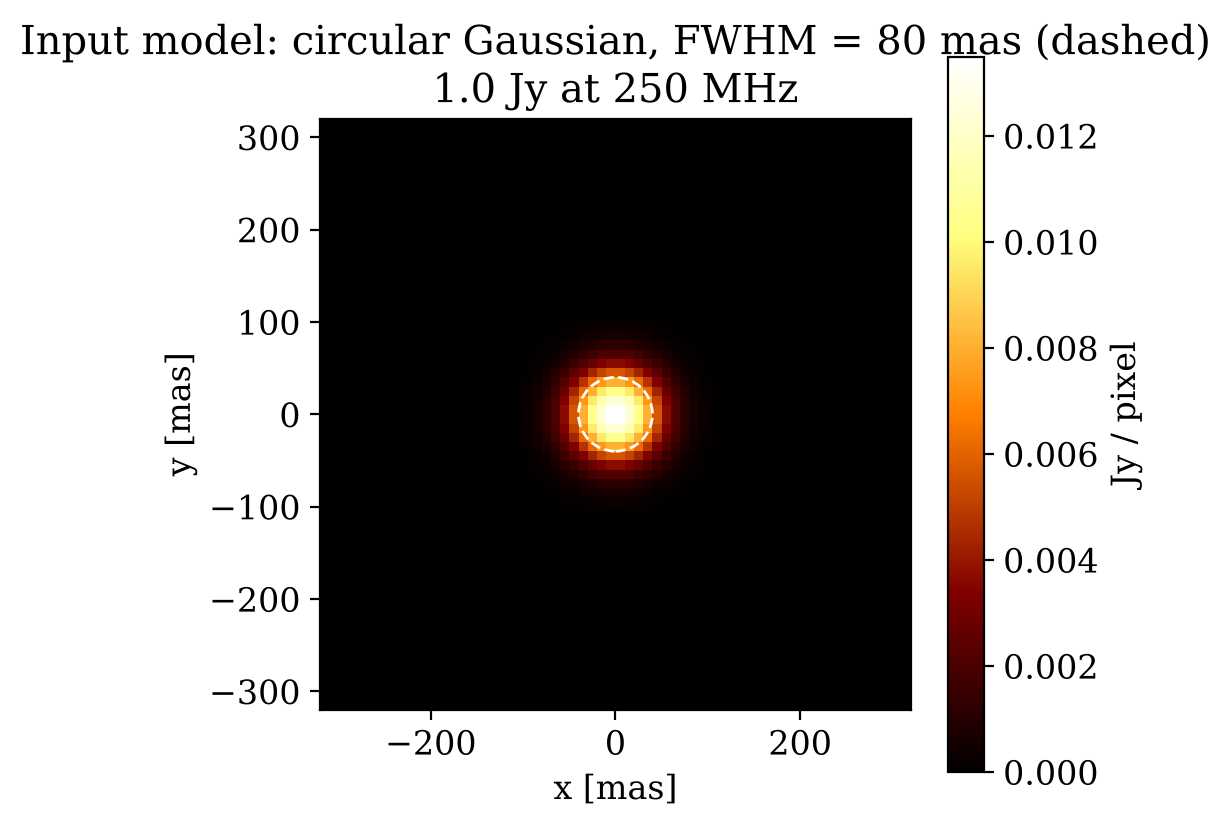

In [4]:
mas = eh.RADPERUAS*1e3
half = im_src.fovx()/2/mas
fig, ax = plt.subplots(figsize=(5.2, 4.6))
h = ax.imshow(im_src.imvec.reshape(im_src.ydim, im_src.xdim), cmap='afmhot', extent=[-half, half, -half, half])
ax.add_patch(plt.Circle((0, 0), src_fwhm_mas/2, fill=False, ls='--', lw=1, color='w'))
ax.set(title=f'Input model: circular Gaussian, FWHM = {src_fwhm_mas:.0f} mas (dashed)\n{im_src.total_flux():.1f} Jy at {nu/1e6:.0f} MHz',
       xlabel='x [mas]', ylabel='y [mas]')
plt.colorbar(h, label='Jy / pixel'); plt.tight_layout(); save_fig(fig, '01_input_model'); plt.show()

## 3. Reference observation (no errors)

Not one of the scenarios: it is the error-free reference against which A, B and C are compared.

In [5]:
obs_ideal = im_src.observe(array_lba, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='fast',
                          elevmin=elevation_min, add_th_noise=False, ampcal=True, phasecal=True)
obs_ideal.add_all(avg_time=avg_time)
print(f"{len(obs_ideal.data)} visibility rows, {len(set(zip(obs_ideal.data['t1'], obs_ideal.data['t2'])))} baselines")

Generating empty observation file . . . 
Producing clean visibilities from image with fast FT . . . 
Adding gain + phase errors to data and applying a priori calibration . . . 


Updated self.amp: no averaging
Updated self.amp: avg_time 30.000000 s

Updated self.bispec: no averaging
Updated self.bispec: avg_time 30.000000 s



Updated self.cphase: no averaging
updated self.cphase: avg_time 30.000000 s

Diagonalizing closure phases:: type vis, count min, scan 1/96 

Diagonalizing closure phases:: type vis, count min, scan 2/96 

Diagonalizing closure phases:: type vis, count min, scan 3/96 

Diagonalizing closure phases:: type vis, count min, scan 4/96 

... (188 outputs left out)

Diagonalizing log closure amplitudes:: type vis, count min, scan 94/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 95/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 96/96 

updated self.logcamp_diag: avg_time 30.000000 s

1850 visibility rows, 21 baselines


**Baselines and closure triangles with signal.** The cell below counts, for the chosen source size, the baselines whose median SNR (noise-free amplitude over the thermal-noise `sigma`) exceeds 5, and the closure triangles with all three legs above that threshold. These are the data the closure-based imaging can actually use.

In [6]:
import itertools
snr = {}
for b in sorted(set(zip(obs_ideal.data['t1'], obs_ideal.data['t2']))):
    m = (obs_ideal.data['t1'] == b[0]) & (obs_ideal.data['t2'] == b[1])
    snr[b] = np.median(np.abs(obs_ideal.data['vis'][m])/obs_ideal.data['sigma'][m])
site_list = list(array_lba.tarr['site'])
leg = lambda a, b: snr.get((a, b), snr.get((b, a), 0.0))
tri = list(itertools.combinations(site_list, 3))
good = [t for t in tri if all(leg(x, y) > 5 for x, y in ((t[0], t[1]), (t[1], t[2]), (t[0], t[2])))]
print(f"Baselines with median SNR > 5: {sum(v > 5 for v in snr.values())}/{len(snr)}")
print(f"Closure triangles with SNR > 5 on all three baselines: {len(good)}/{len(tri)}")

Baselines with median SNR > 5: 17/21
Closure triangles with SNR > 5 on all three baselines: 19/35


## 4. Scenario A: thermal noise only

Stations are perfectly calibrated; the only corruption is receiver thermal noise.

In [7]:
obs_A = im_src.observe(array_lba, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='fast',
                      elevmin=elevation_min, add_th_noise=True, ampcal=True, phasecal=True, seed=1)
obs_A.add_all(avg_time=avg_time); obs_A.add_scans()
print(f"Scenario A: median SNR = {np.median(np.abs(obs_A.data['vis'])/obs_A.data['sigma']):.1f}")

Generating empty observation file . . . 

Producing clean visibilities from image with fast FT . . . 
Adding gain + phase errors to data and applying a priori calibration . . . 
Adding thermal noise to data . . . 


Updated self.amp: no averaging
Updated self.amp: avg_time 30.000000 s

Updated self.bispec: no averaging
Updated self.bispec: avg_time 30.000000 s



Updated self.cphase: no averaging
updated self.cphase: avg_time 30.000000 s

Diagonalizing closure phases:: type vis, count min, scan 1/96 

Diagonalizing closure phases:: type vis, count min, scan 2/96 

Diagonalizing closure phases:: type vis, count min, scan 3/96 

... (189 outputs left out)

Diagonalizing log closure amplitudes:: type vis, count min, scan 94/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 95/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 96/96 



updated self.logcamp_diag: avg_time 30.000000 s

Scenario A: median SNR = 26.8


## 5. Scenario B: thermal noise + gain errors + generic phase errors

Gain errors (`gain_offset`, `gainp`) and `phasecal=False`, so `ehtim` adds its own random, independent per-timestamp, per-station phase.

In [8]:
obs_B = im_src.observe(array_lba, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='fast',
                      elevmin=elevation_min, add_th_noise=True,
                      ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val,
                      phasecal=False, seed=2)
obs_B.add_all(avg_time=avg_time); obs_B.add_scans()
print(f"Scenario B: {len(obs_B.data)} rows")

Generating empty observation file . . . 


Producing clean visibilities from image with fast FT . . . 

Adding gain + phase errors to data and applying a priori calibration . . . 
   Applying gain corruption: ampcal-->False
   Applying atmospheric phase corruption: phasecal-->False
Adding thermal noise to data . . . 


Updated self.amp: no averaging
Updated self.amp: avg_time 30.000000 s



Updated self.bispec: no averaging
Updated self.bispec: avg_time 30.000000 s



Updated self.cphase: no averaging
updated self.cphase: avg_time 30.000000 s

Diagonalizing closure phases:: type vis, count min, scan 1/96 

... (191 outputs left out)

Diagonalizing log closure amplitudes:: type vis, count min, scan 94/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 95/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 96/96 



updated self.logcamp_diag: avg_time 30.000000 s

Scenario B: 1850 rows


## 6. Scenario C: thermal noise + gain errors + structured ionospheric / delay phase errors

Same noise and gain budget as B, but `phasecal=True` (no `ehtim` phase noise); the phase errors come from a physical screen. Per station $i$:

$$\phi_i(t,\nu)=\frac{K\,\mathrm{dTEC}_i(t)}{\nu}+2\pi\nu\,\tau_i(t),\qquad K=8.448\times10^{9}\ \mathrm{rad\,Hz/TECU}.$$

At 250 MHz, 1 TECU is **33.8 rad** (≈ 6.8 rad across the 50 MHz band). The screen has a static per-station offset plus a random walk (TECU/√min), and each visibility is multiplied by $\Gamma_{ij}=\langle e^{i(\phi_i-\phi_j)}\rangle$ averaged over `n_chan` channels and sub-integrations of the scan. $\Gamma_{ij}$ is **not antenna-based**, so self-cal and closure quantities cannot fully remove it. The thermal noise is added *after* the screen so that the decorrelation attenuates the signal but not the noise.

The `dtec0_sigma`, `dtec_rate`, `tau0_sigma_ns` and `tau_rate_ns` values are illustrative, not measured; vary them.

In [9]:
K = 8.4479745e9   # rad Hz / TECU

def make_screens(sites, t0_h, t1_h, dtec0_sigma=0.3, dtec_rate=0.02,
                 tau0_sigma_ns=0.5, tau_rate_ns=0.01, dt_s=10.0, seed=42):
    # dtec0_sigma [TECU]: static offset; dtec_rate [TECU/sqrt(min)]: random-walk rate.
    rng = np.random.default_rng(seed)
    n = len(sites); ng = int(np.ceil((t1_h - t0_h)*3600/dt_s)) + 2
    tg = t0_h + np.arange(ng)*dt_s/3600.0
    s = np.sqrt(dt_s/60.0)
    dtec = dtec0_sigma*rng.normal(size=(n, 1))   + np.cumsum(rng.normal(0, dtec_rate*s,   (n, ng)), axis=1)
    tau  = tau0_sigma_ns*rng.normal(size=(n, 1)) + np.cumsum(rng.normal(0, tau_rate_ns*s, (n, ng)), axis=1)
    return {'sites': list(sites), 't': tg, 'dtec': dtec, 'tau_ns': tau}

def phase_at(scr, i, t_h, nu_hz):
    d   = np.interp(t_h, scr['t'], scr['dtec'][i])
    tau = np.interp(t_h, scr['t'], scr['tau_ns'][i])
    return K*d/nu_hz + 2*np.pi*nu_hz*tau*1e-9

def apply_iono(obs, scr, nu0, bw, n_chan=32, tint=120.0, n_sub=24,
               add_noise=True, seed=3, decorrelate=True):
    out = obs.copy(); d = out.data
    idx = {s: i for i, s in enumerate(scr['sites'])}
    i1 = np.array([idx[s] for s in d['t1']]); i2 = np.array([idx[s] for s in d['t2']])
    nuc = nu0 + (np.arange(n_chan) - (n_chan-1)/2)*bw/n_chan if decorrelate else np.array([nu0])
    sub = ((np.arange(n_sub) if decorrelate else np.array([(n_sub-1)/2])) - (n_sub-1)/2)*tint/n_sub/3600.0
    tt = d['time'][:, None] + sub[None, :]
    G = np.zeros(len(d), complex)
    for k in range(len(d)):
        a = np.array([phase_at(scr, i1[k], tt[k], f) for f in nuc])
        b = np.array([phase_at(scr, i2[k], tt[k], f) for f in nuc])
        G[k] = np.exp(1j*(a - b)).mean()
    for c in d.dtype.names:
        if c.endswith('vis'): d[c] = d[c]*G
    if add_noise:
        rng = np.random.default_rng(seed)
        for c, sg in (('vis', 'sigma'), ('qvis', 'qsigma'), ('uvis', 'usigma'), ('vvis', 'vsigma')):
            d[c] = d[c] + rng.normal(0, d[sg]) + 1j*rng.normal(0, d[sg])
    return out, G

# base: gain errors, NO thermal noise, NO ehtim phase errors
obs_C0 = im_src.observe(array_lba, tint, tadv, tstart, tstop, bw, sgrscat=False, ttype='fast',
                       elevmin=elevation_min, add_th_noise=False,
                       ampcal=False, gain_offset=gain_offset_val, gainp=gainp_val, phasecal=True, seed=4)
scr = make_screens(array_lba.tarr['site'], tstart, tstop)
obs_C, G = apply_iono(obs_C0, scr, nu, bw, n_chan=n_chan, tint=tint)
obs_C.add_all(avg_time=avg_time); obs_C.add_scans()
print(f"Scenario C: {len(obs_C.data)} rows | |G| mean = {np.mean(np.abs(G)):.2f}, min = {np.abs(G).min():.2f} (1 = no decorrelation)")
print(f"Phase per TECU at {nu/1e6:.0f} MHz: {K/nu:.1f} rad")

Generating empty observation file . . . 


Producing clean visibilities from image with fast FT . . . 


Adding gain + phase errors to data and applying a priori calibration . . . 
   Applying gain corruption: ampcal-->False


Updated self.amp: no averaging
Updated self.amp: avg_time 30.000000 s

Updated self.bispec: no averaging
Updated self.bispec: avg_time 30.000000 s



Updated self.cphase: no averaging
updated self.cphase: avg_time 30.000000 s

Diagonalizing closure phases:: type vis, count min, scan 1/96 

Diagonalizing closure phases:: type vis, count min, scan 2/96 

... (190 outputs left out)

Diagonalizing log closure amplitudes:: type vis, count min, scan 94/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 95/96 

Diagonalizing log closure amplitudes:: type vis, count min, scan 96/96 



updated self.logcamp_diag: avg_time 30.000000 s

Scenario C: 1850 rows | |G| mean = 0.47, min = 0.02 (1 = no decorrelation)
Phase per TECU at 250 MHz: 33.8 rad


## 7. Self-calibration (oracle reference) and closure check

The self-calibration in the first cell uses the **true model** (an *oracle*): it is a best-case reference and is **not** used by `pipeline_3rounds`, which self-calibrates to its own previous image (Section 8). The visibilities of a centred circular Gaussian are real and positive, so its closure phases are zero and their scatter is a clean diagnostic: antenna-based gain and phase errors cancel in closure phases, so in A and B it reflects thermal noise only, while in C the non-antenna-based decorrelation adds extra scatter.

In [10]:
cal_B_oracle = sc.self_cal(obs_B, im_src, ttype='fast', scan_solutions=True, processes=1)
cal_C_oracle = sc.self_cal(obs_C, im_src, ttype='fast', scan_solutions=True, processes=1)

def cphase_rms(obs):
    cp = obs.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
    return np.sqrt(np.mean(np.asarray(cp['cphase'])**2)), len(cp)

# Sanity check: phase screen only (no decorrelation, no noise) must leave closure phases unchanged
obs_Cp, _ = apply_iono(obs_C0, scr, nu, bw, add_noise=False, decorrelate=False)
cp0 = obs_C0.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
cp1 = obs_Cp.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
print(f"Phase screen only: max |change in closure phase| = {np.abs((cp1['cphase']-cp0['cphase']+180)%360-180).max():.1e} deg")
for name, o in (('A', obs_A), ('B', obs_B), ('C', obs_C)):
    r, n = cphase_rms(o); print(f"Scenario {name}: closure-phase rms = {r:6.2f} deg  ({n} triangles)")

No stations specified in self cal: defaulting to calibrating all stations!
Computing the Model Visibilities with fast Fourier Transform...
Producing clean visibilities from image with fast FT . . . 


Using Multiprocessing with 1 Processes

Scan 01/96 : [                              ]1%

Scan 02/96 : [                              ]2%

Scan 03/96 : [                              ]3%

Scan 04/96 : [-                             ]4%

... (189 outputs left out)


self_cal time: 11.177399 s


Phase screen only: max |change in closure phase| = 6.3e-13 deg
Scenario A: closure-phase rms =  53.14 deg  (1302 triangles)


Scenario B: closure-phase rms =  50.32 deg  (1302 triangles)


Scenario C: closure-phase rms =  74.67 deg  (1302 triangles)


## 8. Imaging: closure quantities vs. raw visibilities

The imaging uses `ehtim`'s regularized-maximum-likelihood (RML) imager in several rounds. `run_pipeline` adds **iterative self-calibration**: before a round marked `'selfcal'`, the *raw* data are self-calibrated to the image reconstructed so far (never to the true model).

**Reconstruction grid.** ~8 mas pixels (`npix_rec`, `fov_beams` in Section 1), about 6 per beam. Finer pixels only make the image smoother: the resolution stays at the LBA + SKA-Low beam. The regularizer weights (`w_simple`, `w_tv`) are set for this grid.

**Prior.** A Gaussian of one nominal beam FWHM, a source-agnostic choice. A prior much larger than the resolution can keep a closure-only first round from converging.

**`pipeline_3rounds`** is the single pipeline used for A, B and C:
1. Round 1 fits only gain-invariant closure quantities (`cphase`, `logcamp`) on the raw data.
2. The raw data are self-calibrated (amplitude and phase) to the round-1 image; round 2 fits the bispectrum and the visibility amplitudes.
3. The raw data are self-calibrated again to the round-2 image; round 3 refines with total variation.

`pipeline_oracle` has the same structure but self-calibrates to the true model (best case). `closure_rounds_handson` is the closure-based imaging strategy of the `ehtim` hands-on, run on the oracle-calibrated data as a reference.

**Final restoring beam.** The data constrain nothing below the resolution of the LBA + SKA-Low array, so each final image is blurred once, at the end, with a Gaussian equal to the **fitted dirty beam** (`obs.fit_beam`, uniform weighting by default; `beam_weighting = 'natural'` gives a broader, more conservative beam). This beam is elliptical and larger than the nominal `1/uvmax` resolution, which is only the best case along the longest baseline. The metrics compare the restored reconstruction with the true model restored with the same beam. The blur between rounds (`blur_frac`) is a separate imaging setting.

In [11]:
class LoggedImager(eh.imager.Imager):
    # Imager that records the reduced chi^2 of every active data term at each iteration (iteration 0 = initial image).
    def plotcur(self, imvec, **kwargs):
        if getattr(self, 'history', None) is not None:
            chi2 = self.make_chisq_dict(np.exp(imvec))          # the optimizer works on the log-image
            self.history.append({'round': self.round_id, 'iter': self._nit, **{k: float(v) for k, v in chi2.items()}})
        super().plotcur(imvec, **kwargs)

def run_rml_imager(obs, prior, flux, rounds, ttype='fast', verbose=False, obs_alt=None, history=None):
    # If `history` is a list, the reduced chi^2 of each data term is appended to it at every iteration.
    imgr = None; out = prior; current_obs = obs
    for i, rnd in enumerate(rounds):
        key = rnd.get('switch_obs')
        if key is not None and obs_alt and key in obs_alt:
            current_obs = obs_alt[key]
            if verbose: print(f"  -> Round {i+1}/{len(rounds)}: switching obs to '{key}', data_term={list(rnd['data_term'])}")
        elif verbose:
            print(f"  -> Round {i+1}/{len(rounds)}: data_term={list(rnd['data_term'])}")
        blur_frac = rnd.get('blur_frac', 0.0)
        init_im = out.blur_circ(blur_frac*current_obs.res()) if blur_frac > 0 else out
        if imgr is None:
            Imgr = LoggedImager if history is not None else eh.imager.Imager
            imgr = Imgr(current_obs, init_im, init_im, flux, data_term=rnd['data_term'],
                        reg_term=rnd['reg_term'], maxit=rnd['maxit'], ttype=ttype)
            imgr.history = history
        else:
            imgr.obslist_next = [current_obs]; imgr.init_next = init_im; imgr.prior_next = init_im
            imgr.dat_term_next = rnd['data_term']; imgr.reg_term_next = rnd['reg_term']; imgr.maxit_next = rnd['maxit']
        imgr.round_id = i
        plt.ioff()
        with contextlib.redirect_stdout(io.StringIO()):
            out = imgr.make_image_I(show_updates=False)
        plt.close('all'); plt.ion()
    return out

CHI2_COLORS = {'cphase': 'tab:blue', 'logcamp': 'tab:orange', 'bs': 'tab:green', 'amp': 'tab:red', 'vis': 'tab:purple'}

def plot_chi2_histories(hists, fname, title, ncols=3):
    # One panel per reconstruction: reduced chi^2 of every active data term at every iteration, cumulative over
    # the rounds (dashed lines = start of a new round, dotted line = chi^2 of 1).
    keys = [k for k in hists if hists[k]]
    nrows = int(np.ceil(len(keys)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 3.8*nrows), squeeze=False)
    for ax, k in zip(axes.ravel(), keys):
        h = hists[k]; off = 0; edges = []; seen = set()
        for r in sorted({x['round'] for x in h}):
            rec = [x for x in h if x['round'] == r]
            xs = off + np.array([x['iter'] for x in rec])
            for t, c in CHI2_COLORS.items():
                if t in rec[0]:
                    ax.semilogy(xs, [x[t] for x in rec], color=c, lw=1.4, label=None if t in seen else t); seen.add(t)
            off = xs.max() + 1; edges.append(off)
        for e in edges[:-1]: ax.axvline(e, color='gray', ls='--', lw=0.8)
        ax.axhline(1, color='k', ls=':', lw=0.8)
        ax.set_title(k if isinstance(k, str) else f'{k[1]}: {k[0]}', fontsize=9)
        ax.set_xlabel('iteration (cumulative over rounds)', fontsize=8); ax.legend(fontsize=7, loc='upper right')
    for ax in axes.ravel()[len(keys):]: ax.axis('off')
    for ax in axes[:, 0]: ax.set_ylabel(r'reduced $\chi^2$')
    fig.suptitle(title, fontsize=12); plt.tight_layout(); save_fig(fig, fname); plt.show()

def run_pipeline(obs, prior, flux, rounds, ttype='fast', model=None, final_beam=None, history=None):
    # Like run_rml_imager, but a round with 'selfcal' in {'phase','both'} first self-calibrates the RAW data
    # to the image obtained so far; 'oracle' self-calibrates to `model` (the true image) instead.
    # If `final_beam` = [major, minor, PA] [rad] is given, the final image is restored (blurred) with that Gaussian.
    # If `history` is a list, the reduced chi^2 of each data term is appended to it at every iteration.
    imgr = None; out = prior; current = obs
    for i, rnd in enumerate(rounds):
        m = rnd.get('selfcal')
        if m:
            with contextlib.redirect_stdout(io.StringIO()):
                if m == 'oracle':
                    current = sc.self_cal(obs, model, method='both', ttype=ttype, scan_solutions=True, processes=1)
                else:
                    current = sc.self_cal(obs, out, method=m, ttype=ttype, scan_solutions=True, processes=1)
        bf = rnd.get('blur_frac', 0.0)
        init_im = out.blur_circ(bf*current.res()) if bf > 0 else out
        if imgr is None:
            Imgr = LoggedImager if history is not None else eh.imager.Imager
            imgr = Imgr(current, init_im, init_im, flux, data_term=rnd['data_term'],
                        reg_term=rnd['reg_term'], maxit=rnd['maxit'], ttype=ttype)
            imgr.history = history
        else:
            imgr.obslist_next = [current]; imgr.init_next = init_im; imgr.prior_next = init_im
            imgr.dat_term_next = rnd['data_term']; imgr.reg_term_next = rnd['reg_term']; imgr.maxit_next = rnd['maxit']
        imgr.round_id = i
        plt.ioff()
        with contextlib.redirect_stdout(io.StringIO()):
            out = imgr.make_image_I(show_updates=False)
        plt.close('all'); plt.ion()
    if final_beam is None:
        return out
    restored = out.blur_gauss(final_beam, frac=1.0)
    restored.unrestored = out          # unrestored image, used as self-calibration model in Section 11
    return restored

closure_rounds_handson = [
    {'data_term': {'bs': 100},                'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
    {'data_term': {'amp': 50, 'cphase': 100}, 'reg_term': {'tv': 1,  'flux': 1000, 'cm': 50}, 'maxit': 80,  'blur_frac': 1.0},
    {'data_term': {'cphase': 100, 'logcamp': 50}, 'reg_term': {'tv': 10, 'flux': 1000, 'cm': 50}, 'maxit': 100,
     'blur_frac': 0.5, 'switch_obs': 'cal'},
]
FM = {'flux': 1000, 'cm': 50}
w_simple, w_tv = 100, 10     # regularizer weights; x10 w.r.t. a coarse (26 mas) pixel grid, see Section 8 text
CL, BA = {'cphase': 100, 'logcamp': 50}, {'bs': 100, 'amp': 50}
pipeline_3rounds = [
    {'data_term': CL, 'reg_term': {'simple': w_simple, **FM}, 'maxit': 100},
    {'data_term': BA, 'reg_term': {'simple': w_simple, **FM}, 'maxit': 150, 'blur_frac': 1.0, 'selfcal': 'both'},
    {'data_term': BA, 'reg_term': {'tv': w_tv, **FM},      'maxit': 150, 'blur_frac': 0.5, 'selfcal': 'both'},
]
pipeline_oracle = [
    {'data_term': {'bs': 100}, 'reg_term': {'simple': w_simple, **FM}, 'maxit': 100},
    {'data_term': BA, 'reg_term': {'simple': w_simple, **FM}, 'maxit': 150, 'blur_frac': 1.0, 'selfcal': 'oracle'},
    {'data_term': BA, 'reg_term': {'tv': w_tv, **FM},      'maxit': 150, 'blur_frac': 0.5},
]
vis_rounds = [
    {'data_term': {'vis': 100}, 'reg_term': {'simple': 10, 'flux': 1000, 'cm': 50}, 'maxit': 60},
    {'data_term': {'vis': 100}, 'reg_term': {'tv': 1,      'flux': 1000, 'cm': 50}, 'maxit': 180, 'blur_frac': 1.0},
]

beam = obs_A.res(); npix = npix_rec; fov = fov_beams*beam; zbl = im_src.total_flux()
with contextlib.redirect_stdout(io.StringIO()):
    beam_params = obs_A.fit_beam(weighting=beam_weighting)      # fitted dirty beam: [major, minor, PA] in rad
mas = eh.RADPERUAS*1e3
print(f"Dirty beam ({beam_weighting}): {beam_params[0]/mas:.0f} x {beam_params[1]/mas:.0f} mas, PA {np.degrees(beam_params[2]):.0f} deg  (nominal 1/uvmax = {beam/mas:.0f} mas)")
empty = eh.image.make_empty(npix, fov, obs_A.ra, obs_A.dec, rf=nu)
prior = empty.add_gauss(zbl, [beam, beam, 0, 0, 0])      # one-beam Gaussian prior
print(f"Resolution: {beam/eh.RADPERUAS/1e3:.0f} mas | FOV: {fov/eh.RADPERUAS/1e3:.0f} mas | pixel: {fov/npix/eh.RADPERUAS/1e3:.1f} mas ({beam/(fov/npix):.1f} px per beam)")

recs = {}
hist = {}        # chi^2 history (every data term, every iteration) of EVERY reconstruction below
def _h(name):
    hist[name] = []; return hist[name]
recs['A  3-round pipeline']    = run_pipeline(obs_A, prior, zbl, pipeline_3rounds, final_beam=beam_params, history=_h('A  3-round pipeline'))
recs['B  3-round pipeline']    = run_pipeline(obs_B, prior, zbl, pipeline_3rounds, final_beam=beam_params, history=_h('B  3-round pipeline'))
recs['C  3-round pipeline']    = run_pipeline(obs_C, prior, zbl, pipeline_3rounds, final_beam=beam_params, history=_h('C  3-round pipeline'))
recs['C  oracle self-cal']     = run_pipeline(obs_C, prior, zbl, pipeline_oracle, model=im_src, final_beam=beam_params, history=_h('C  oracle self-cal'))
recs['C  hands-on rounds']     = run_rml_imager(obs_C, prior, zbl, closure_rounds_handson, obs_alt={'cal': cal_C_oracle},
                                                history=_h('C  hands-on rounds')).blur_gauss(beam_params, frac=1.0)
recs['C  raw visibilities']    = run_rml_imager(obs_C, prior, zbl, vis_rounds, history=_h('C  raw visibilities')).blur_gauss(beam_params, frac=1.0)
hist_pipeline = {sc_: hist[f'{sc_}  3-round pipeline'] for sc_ in 'ABC'}      # used by the convergence figure of Section 9


Dirty beam (uniform): 73 x 43 mas, PA 32 deg  (nominal 1/uvmax = 46 mas)
Resolution: 46 mas | FOV: 462 mas | pixel: 7.2 mas (6.4 px per beam)
Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed bispectrum table in cphase chi^2!


Initializing imager data products . . .
Using pre-computed bispectrum table in cphase chi^2!


Initializing imager data products . . .


## 9. Metrics and diagnostics

The table reports, per reconstruction: the flux inside a 1.5-beam aperture centred on the true position divided by the same aperture flux of the (restored) true model, the offset of the image peak from the true position, and the dynamic range (peak over the rms of pixels farther than 3 beams from the peak). Two shift-invariant fidelity scores from `ehtim` are added (`nrmse`: lower is better, `nxcorr`: higher is better), computed between the restored reconstruction and the true model restored with the same beam, after aligning them. They penalise haze and flux errors but ignore the absolute position, which closure-only imaging does not fix. The *total* flux is deliberately not used: with only a handful of antennas the shortest baselines (~300 km) leave large-scale flux unconstrained by the data.

In [12]:
truth_g = im_src.regrid_image(fov, npix).blur_gauss(beam_params, frac=1.0)   # true model on the reconstruction grid, restored with the same beam
truth_arr = truth_g.imvec.reshape(truth_g.ydim, truth_g.xdim); truth_arr = truth_arr*zbl/truth_arr.sum()

def image_metrics(im, flux, beam):
    img = im.imvec.reshape(im.ydim, im.xdim)
    cy, cx = im.ydim//2, im.xdim//2                      # ehtim puts the image centre at pixel N/2
    yy, xx = np.indices(img.shape)
    r_pix = np.hypot(yy-cy, xx-cx)*im.psize
    iy, ix = np.unravel_index(np.argmax(img), img.shape)
    far = np.hypot(yy-iy, xx-ix)*im.psize > 3*beam
    ap_true = truth_arr[r_pix < 1.5*beam].sum()
    return (img[r_pix < 1.5*beam].sum()/ap_true, np.hypot(iy-cy, ix-cx)*im.psize/eh.RADPERUAS/1e3, img.max()/img[far].std())

def fidelity(im):
    xc, nr = im.compare_images(im_src.blur_gauss(beam_params, frac=1.0), blur_frac=0.0, metric=['nxcorr', 'nrmse'])[0]
    return float(xc), float(nr)

print(f"{'reconstruction':24s} {'aper.flux/true':>15s} {'offset [mas]':>13s} {'dyn. range':>11s} {'nrmse':>7s} {'nxcorr':>7s}")
metrics_rows = []
for k, im in recs.items():
    f, off, dr = image_metrics(im, zbl, beam); xc, nr = fidelity(im)
    metrics_rows.append((k, f, off, dr, nr, xc))
    print(f"{k:24s} {f:15.2f} {off:13.1f} {dr:11.1f} {nr:7.2f} {xc:7.2f}")

reconstruction            aper.flux/true  offset [mas]  dyn. range   nrmse  nxcorr
A  3-round pipeline                 0.84           0.0      1825.8    0.20    1.00
B  3-round pipeline                 0.84           0.0      1833.4    0.21    1.00
C  3-round pipeline                 1.04           0.0       831.3    0.12    0.99
C  oracle self-cal                  0.94          21.7       146.1    0.11    0.99
C  hands-on rounds                  0.83          38.9        52.6    0.21    0.98
C  raw visibilities                 0.10         116.7        10.7    2.62    0.85


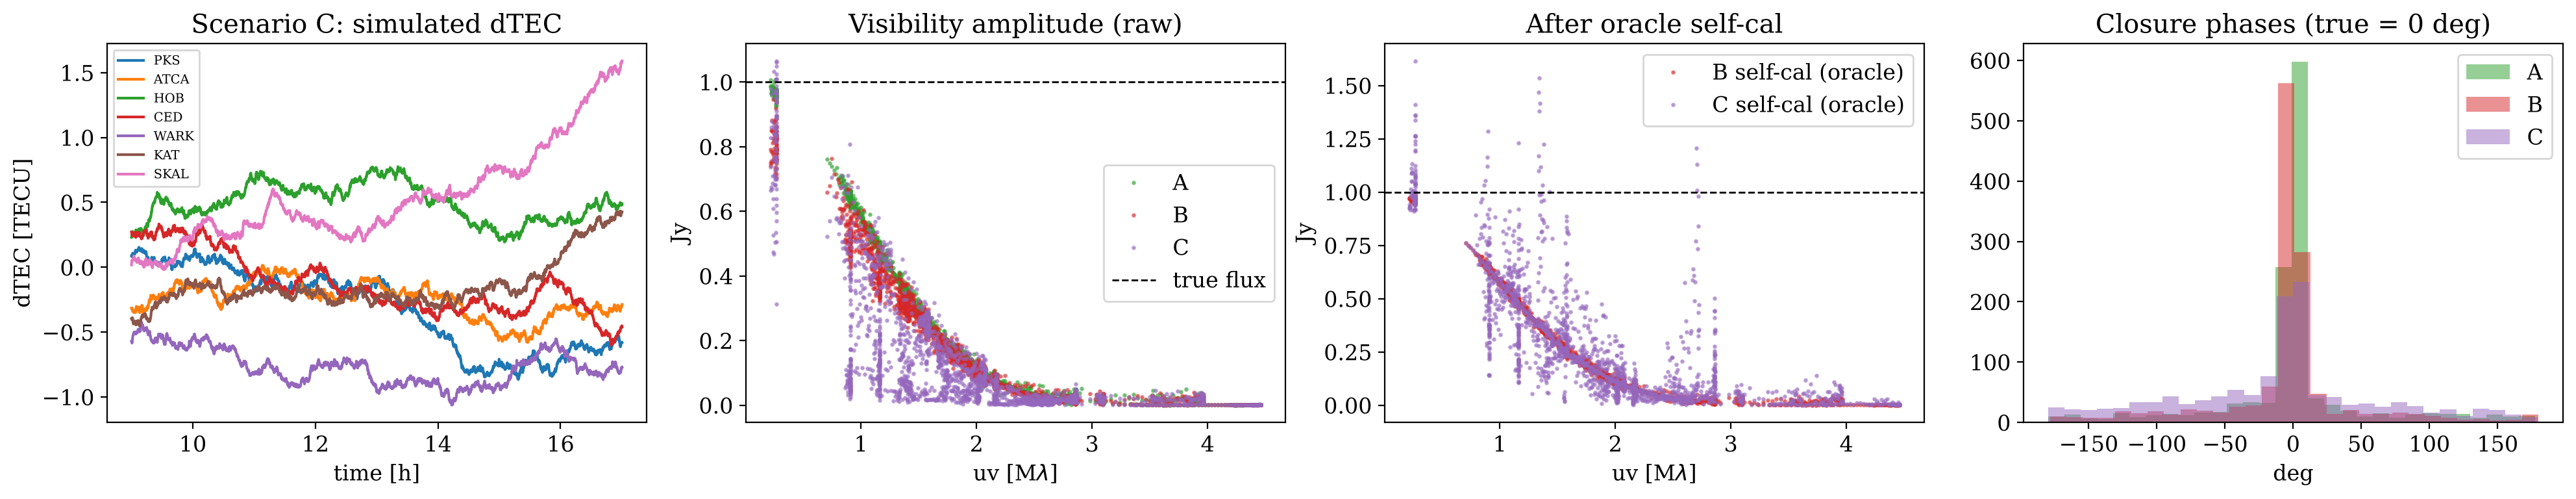

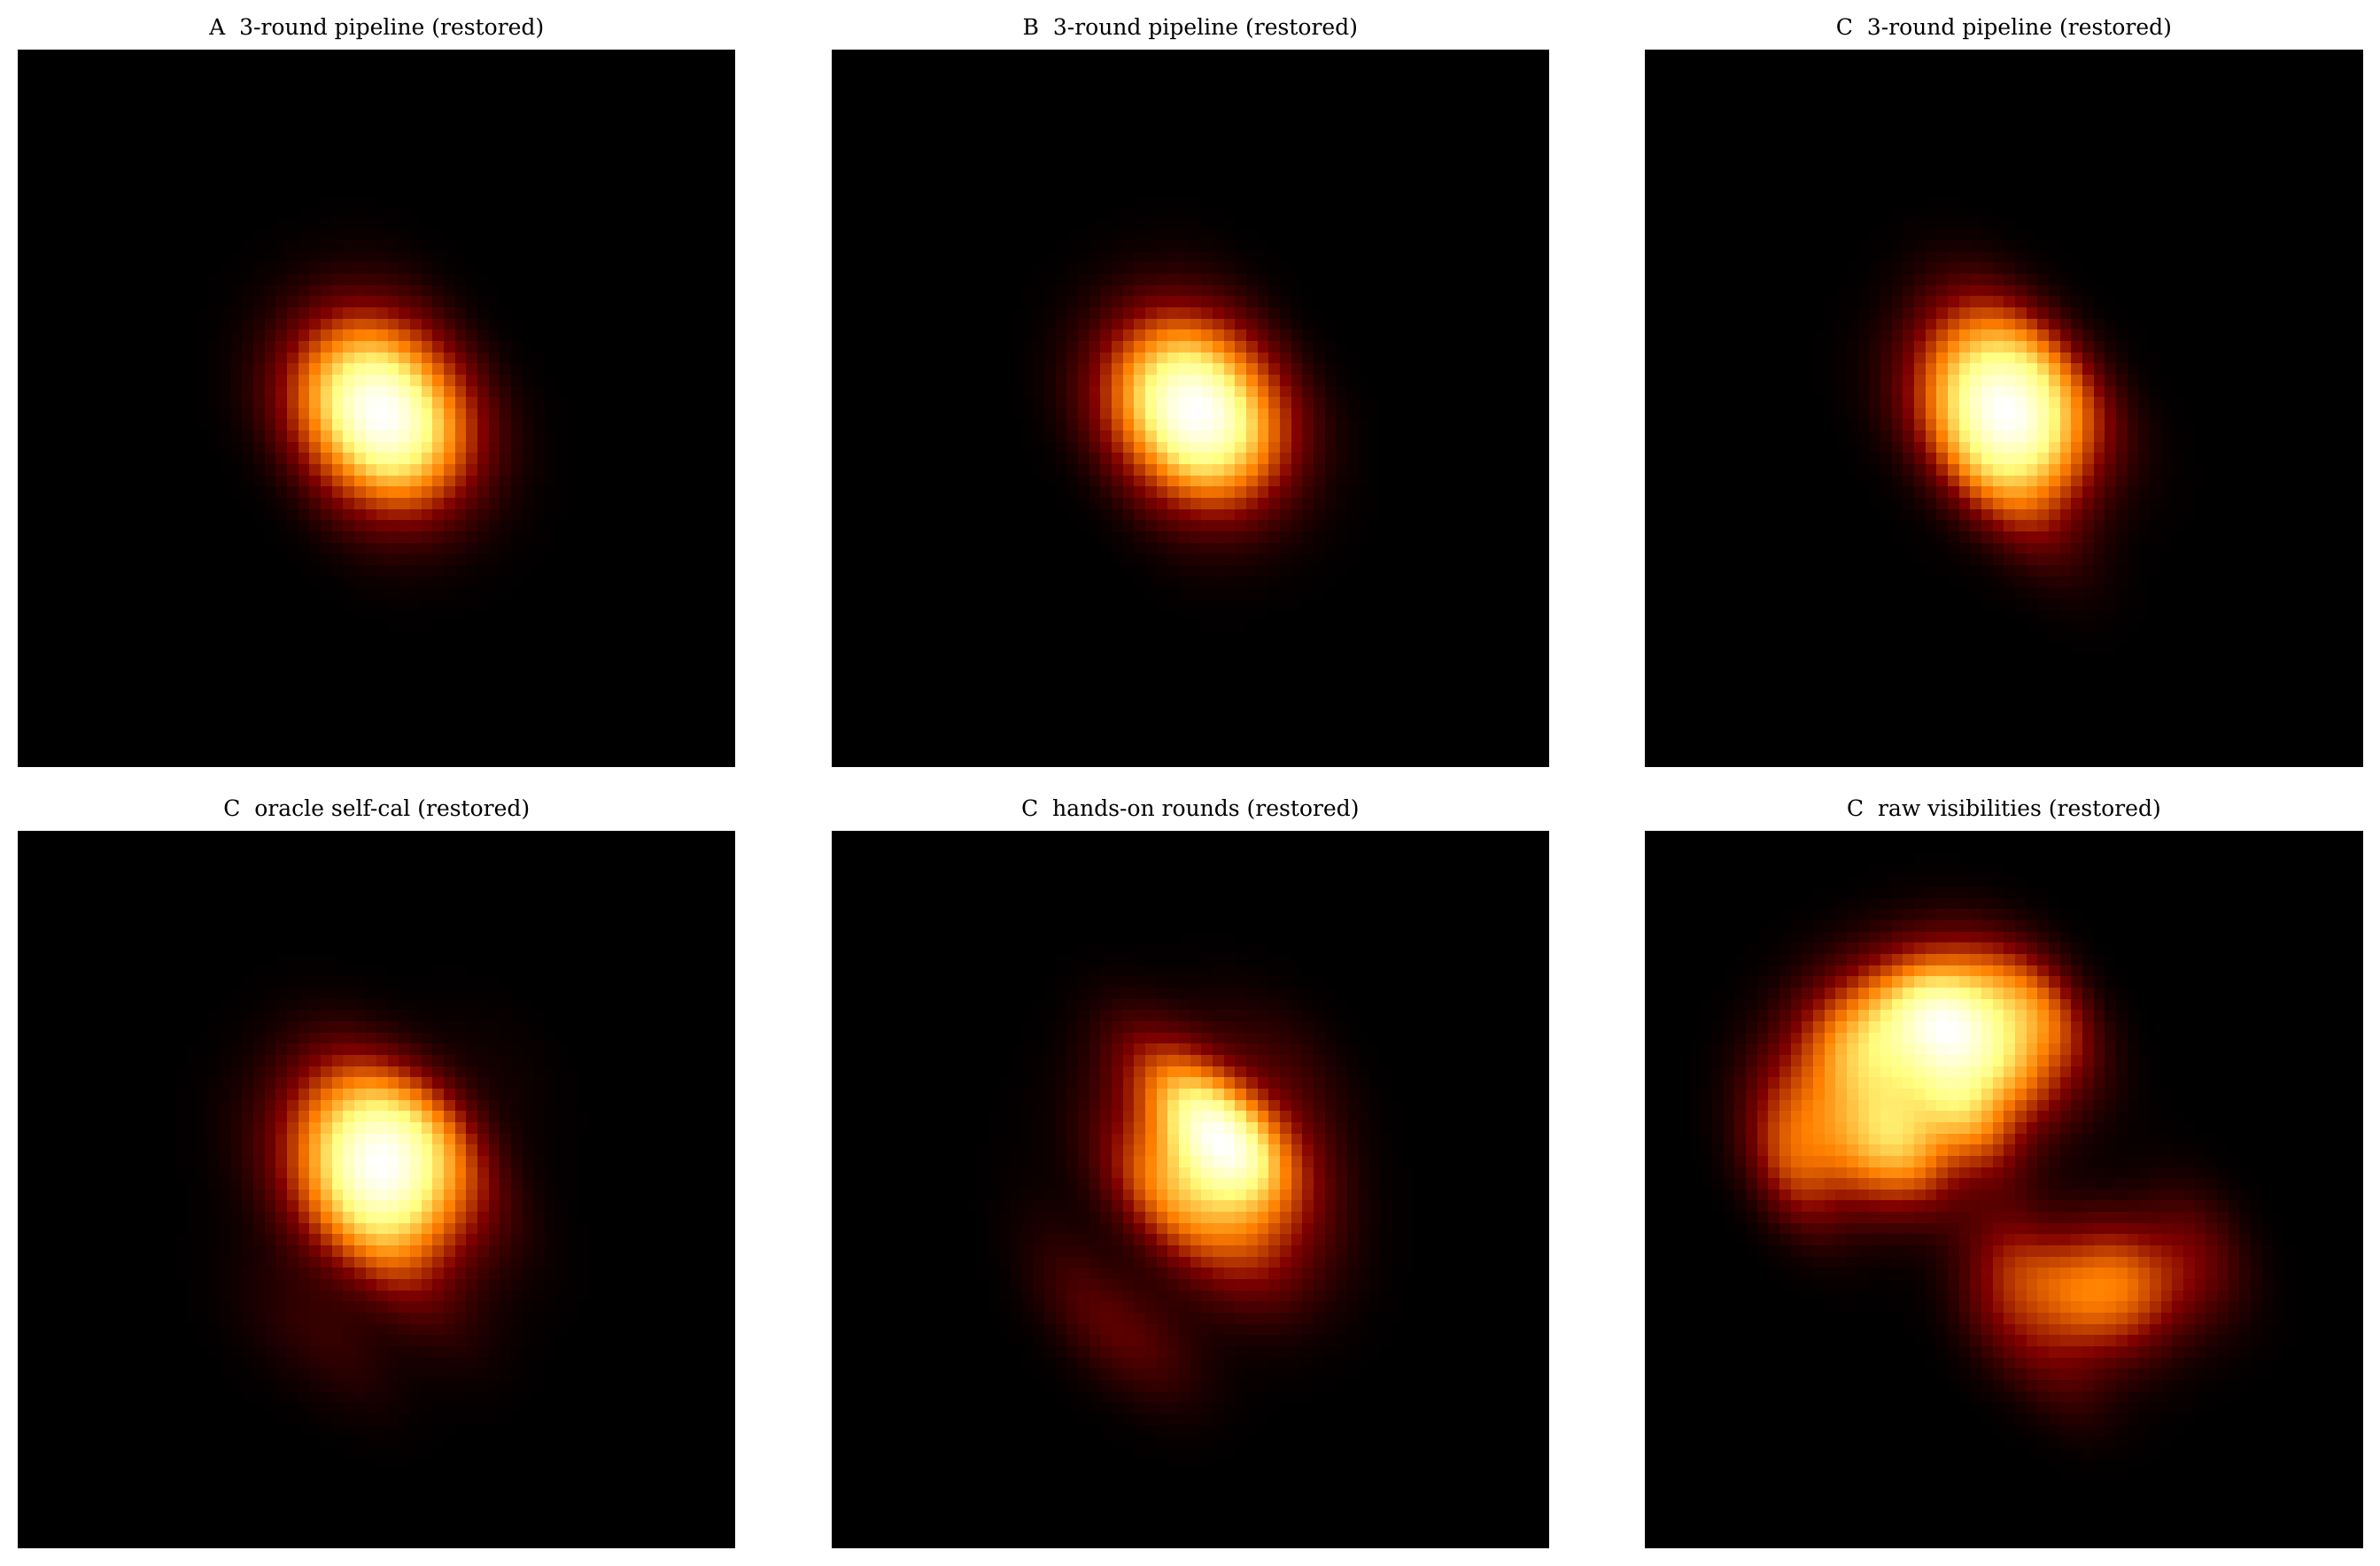

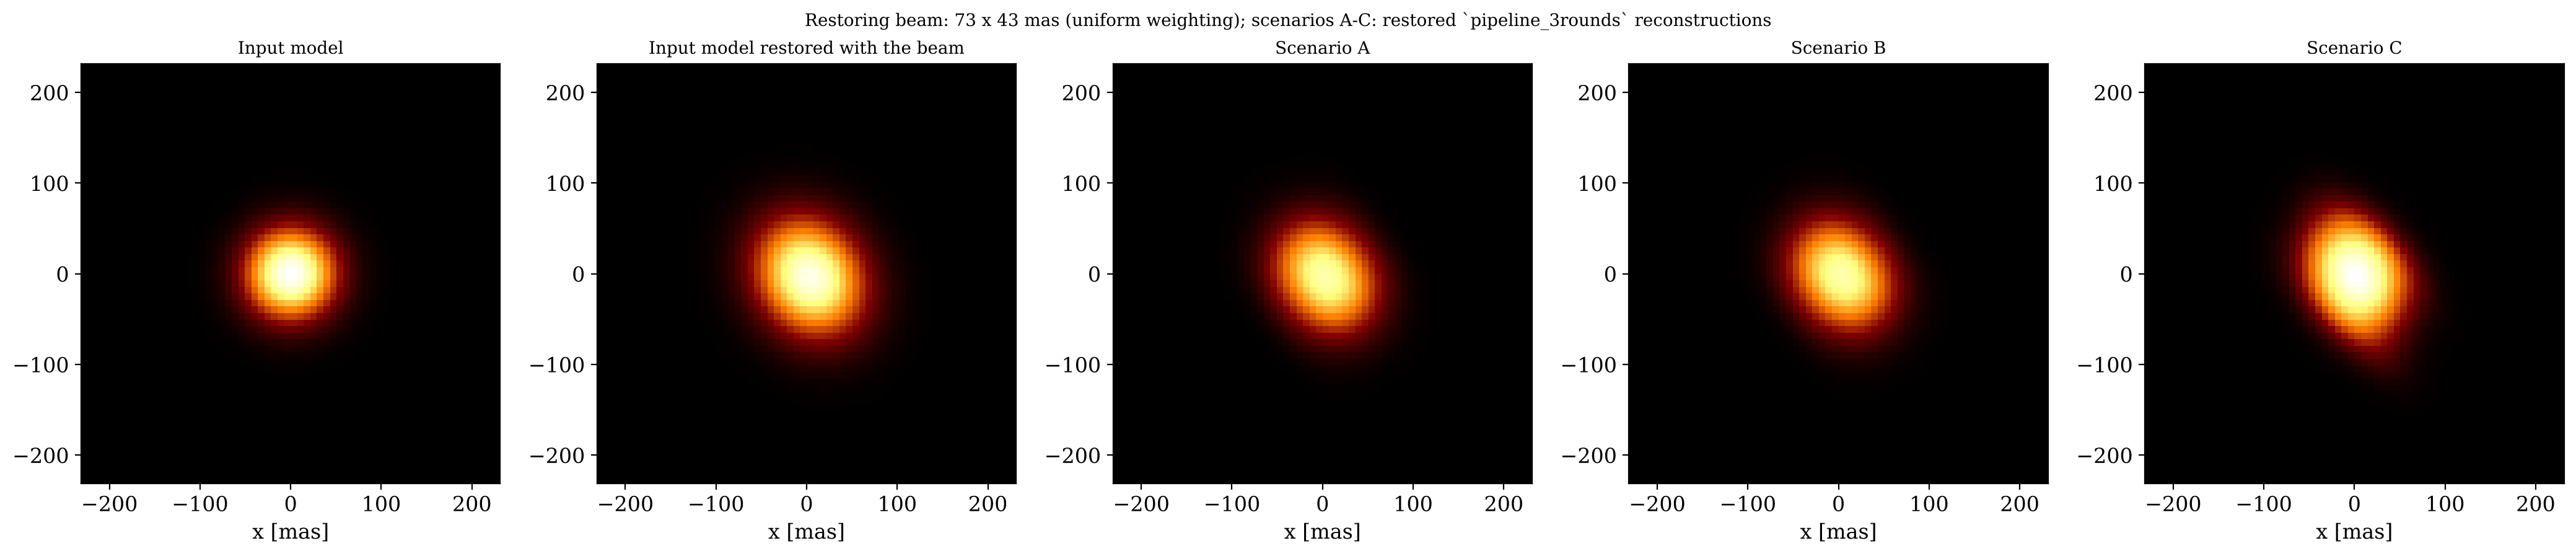

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for i, s in enumerate(scr['sites']): ax[0].plot(scr['t'], scr['dtec'][i], label=s)
ax[0].set(title='Scenario C: simulated dTEC', xlabel='time [h]', ylabel='dTEC [TECU]'); ax[0].legend(fontsize=7)
for name, o, c in (('A', obs_A, 'tab:green'), ('B', obs_B, 'tab:red'), ('C', obs_C, 'tab:purple')):
    uv = np.hypot(o.data['u'], o.data['v'])/1e6
    ax[1].plot(uv, np.abs(o.data['vis']), '.', ms=3, alpha=.5, color=c, label=name)
ax[1].axhline(zbl, color='k', ls='--', lw=1, label='true flux')
ax[1].set(title='Visibility amplitude (raw)', xlabel=r'uv [M$\lambda$]', ylabel='Jy'); ax[1].legend()
for name, o, c in (('B self-cal (oracle)', cal_B_oracle, 'tab:red'), ('C self-cal (oracle)', cal_C_oracle, 'tab:purple')):
    uv = np.hypot(o.data['u'], o.data['v'])/1e6
    ax[2].plot(uv, np.abs(o.data['vis']), '.', ms=3, alpha=.5, color=c, label=name)
ax[2].axhline(zbl, color='k', ls='--', lw=1)
ax[2].set(title='After oracle self-cal', xlabel=r'uv [M$\lambda$]', ylabel='Jy'); ax[2].legend()
for name, o, c in (('A', obs_A, 'tab:green'), ('B', obs_B, 'tab:red'), ('C', obs_C, 'tab:purple')):
    cp = o.c_phases(vtype='vis', mode='all', count='min', ang_unit='deg')
    ax[3].hist(cp['cphase'], bins=30, alpha=.5, color=c, label=name)
ax[3].set(title='Closure phases (true = 0 deg)', xlabel='deg'); ax[3].legend()
plt.tight_layout(); save_fig(fig, '02_diagnostics_dTEC_visibilities_closure'); plt.show()

fig, ax = plt.subplots(2, 3, figsize=(14, 9))
for a, (k, im) in zip(ax.ravel(), recs.items()):
    a.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot'); a.set_title(f'{k} (restored)', fontsize=9); a.axis('off')
plt.tight_layout(); save_fig(fig, '03_reconstructions_all'); plt.show()

fig, ax = plt.subplots(1, 5, figsize=(21, 4.3))
half = fov/2/mas
panels = [('Input model', im_src.regrid_image(fov, npix)), ('Input model restored with the beam', truth_g),
          ('Scenario A', recs['A  3-round pipeline']), ('Scenario B', recs['B  3-round pipeline']),
          ('Scenario C', recs['C  3-round pipeline'])]
vmax = max(p[1].imvec.max() for p in panels[1:])
for k, (a, (t, im)) in enumerate(zip(ax, panels)):
    a.imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[-half, half, -half, half],
             vmin=0, vmax=None if k == 0 else vmax)
    a.set_title(t, fontsize=10); a.set_xlabel('x [mas]')
fig.suptitle(f"Restoring beam: {beam_params[0]/mas:.0f} x {beam_params[1]/mas:.0f} mas ({beam_weighting} weighting); "
             "scenarios A-C: restored `pipeline_3rounds` reconstructions", fontsize=10)
plt.tight_layout(); save_fig(fig, '04_scenarios_A_B_C_vs_truth'); plt.show()

**Convergence of the data fit.** Evolution of the reduced $\chi^2$ of each data term over the iterations of `pipeline_3rounds`, for each scenario observed with the **LBA + SKA-Low** (iterations are cumulative over the three rounds; vertical lines mark the start of rounds 2 and 3, where the data are re-self-calibrated to the image reconstructed so far). A reduced $\chi^2$ of 1 (dotted line) means the model fits the data to within the thermal noise. The terms fitted change from round to round (round 1: closure phases and log closure amplitudes on the raw data; rounds 2 and 3: bispectrum and amplitudes on the self-calibrated data), so a curve is only drawn in the rounds where its term is active, and values are not strictly comparable across rounds. A curve that settles near 1 means the data can be fitted to within the noise; a curve that plateaus well above 1 means that no image, combined with antenna-based calibration, can explain the data, which is what non-antenna-based errors such as the in-band ionospheric decorrelation of scenario C produce.

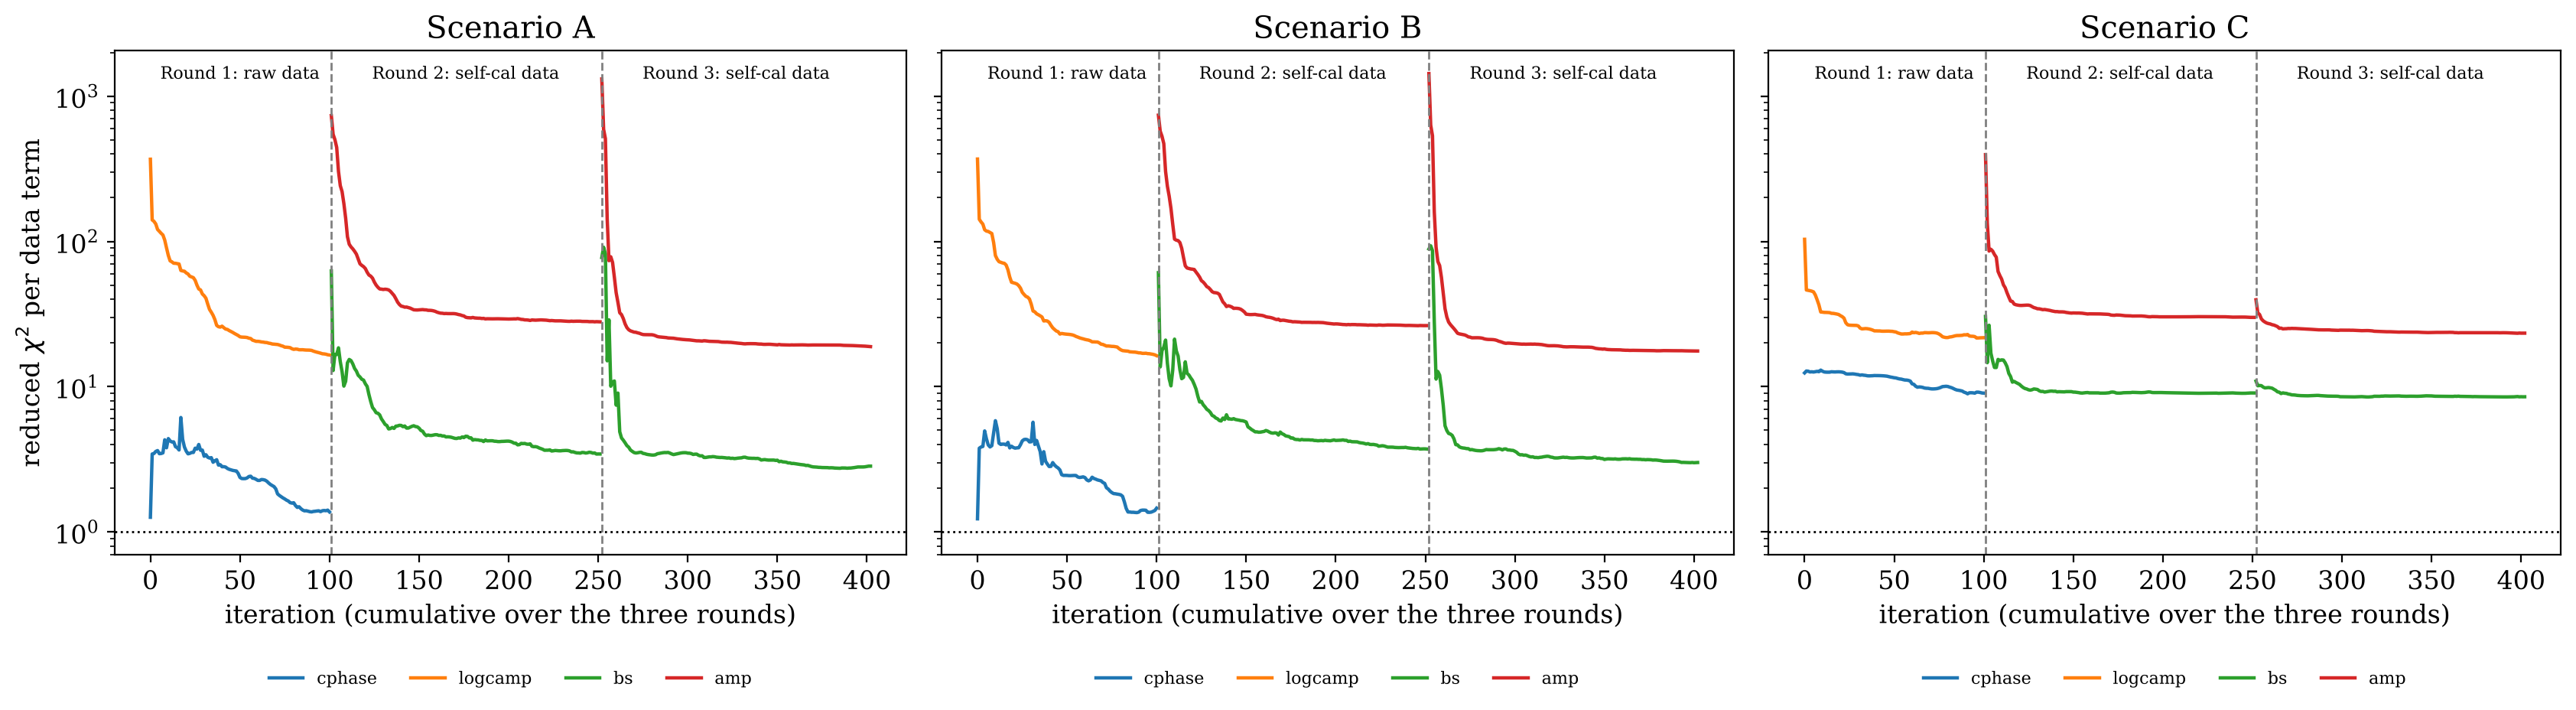

scenario  round   final reduced chi2 per data term
       A      1   cphase = 1.37  logcamp = 16.50
       A      2   bs = 3.44  amp = 27.93
       A      3   bs = 2.83  amp = 18.85
       B      1   cphase = 1.46  logcamp = 16.33
       B      2   bs = 3.72  amp = 26.32
       B      3   bs = 3.00  amp = 17.59
       C      1   cphase = 9.02  logcamp = 21.72
       C      2   bs = 9.04  amp = 29.98
       C      3   bs = 8.51  amp = 23.35


In [14]:
terms = ['cphase', 'logcamp', 'bs', 'amp']
colors = dict(zip(terms, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
round_names = ['Round 1: raw data', 'Round 2: self-cal data', 'Round 3: self-cal data']

fig, ax = plt.subplots(1, 3, figsize=(17, 4.9), sharey=True)
for a, sc_name in zip(ax, 'ABC'):
    h = hist_pipeline[sc_name]; offset = 0; edges = [0]; labelled = set()
    for r in sorted({x['round'] for x in h}):
        rec = [x for x in h if x['round'] == r]
        xs = np.array([offset + x['iter'] for x in rec])
        for t in terms:
            if t in rec[0]:
                a.semilogy(xs, [x[t] for x in rec], color=colors[t], lw=1.6, label=None if t in labelled else t)
                labelled.add(t)
        a.text((offset + xs.max())/2, 0.97, round_names[r], transform=a.get_xaxis_transform(), ha='center', va='top', fontsize=8)
        offset = xs.max() + 1; edges.append(offset)
    for e in edges[1:-1]: a.axvline(e, color='gray', ls='--', lw=1)
    a.axhline(1.0, color='k', ls=':', lw=1)
    a.set(title=f'Scenario {sc_name}', xlabel='iteration (cumulative over the three rounds)')
    a.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8, frameon=False)
ax[0].set_ylabel(r'reduced $\chi^2$ per data term')
plt.tight_layout(); save_fig(fig, '05_chi2_convergence'); plt.show()

print(f"{'scenario':>8s} {'round':>6s}   final reduced chi2 per data term")
for sc_name in 'ABC':
    h = hist_pipeline[sc_name]
    for r in sorted({x['round'] for x in h}):
        last = [x for x in h if x['round'] == r][-1]
        print(f"{sc_name:>8s} {r+1:>6d}   " + '  '.join(f"{t} = {last[t]:.2f}" for t in terms if t in last))

**Convergence of every reconstruction.** The same diagnostic for **all six reconstructions of Section 8** (LBA + SKA-Low), including the oracle self-calibration of C, the closure rounds of the `ehtim` hands-on run on the oracle-calibrated data, and the raw-visibility imaging of C. Each panel shows every active data term at every iteration, cumulative over the rounds (dashed lines: start of a new round; dotted line: $\chi^2 = 1$). The raw-visibility run is the useful contrast: its `vis` term cannot approach 1, because the uncalibrated phases of scenario C are not consistent with any sky image.

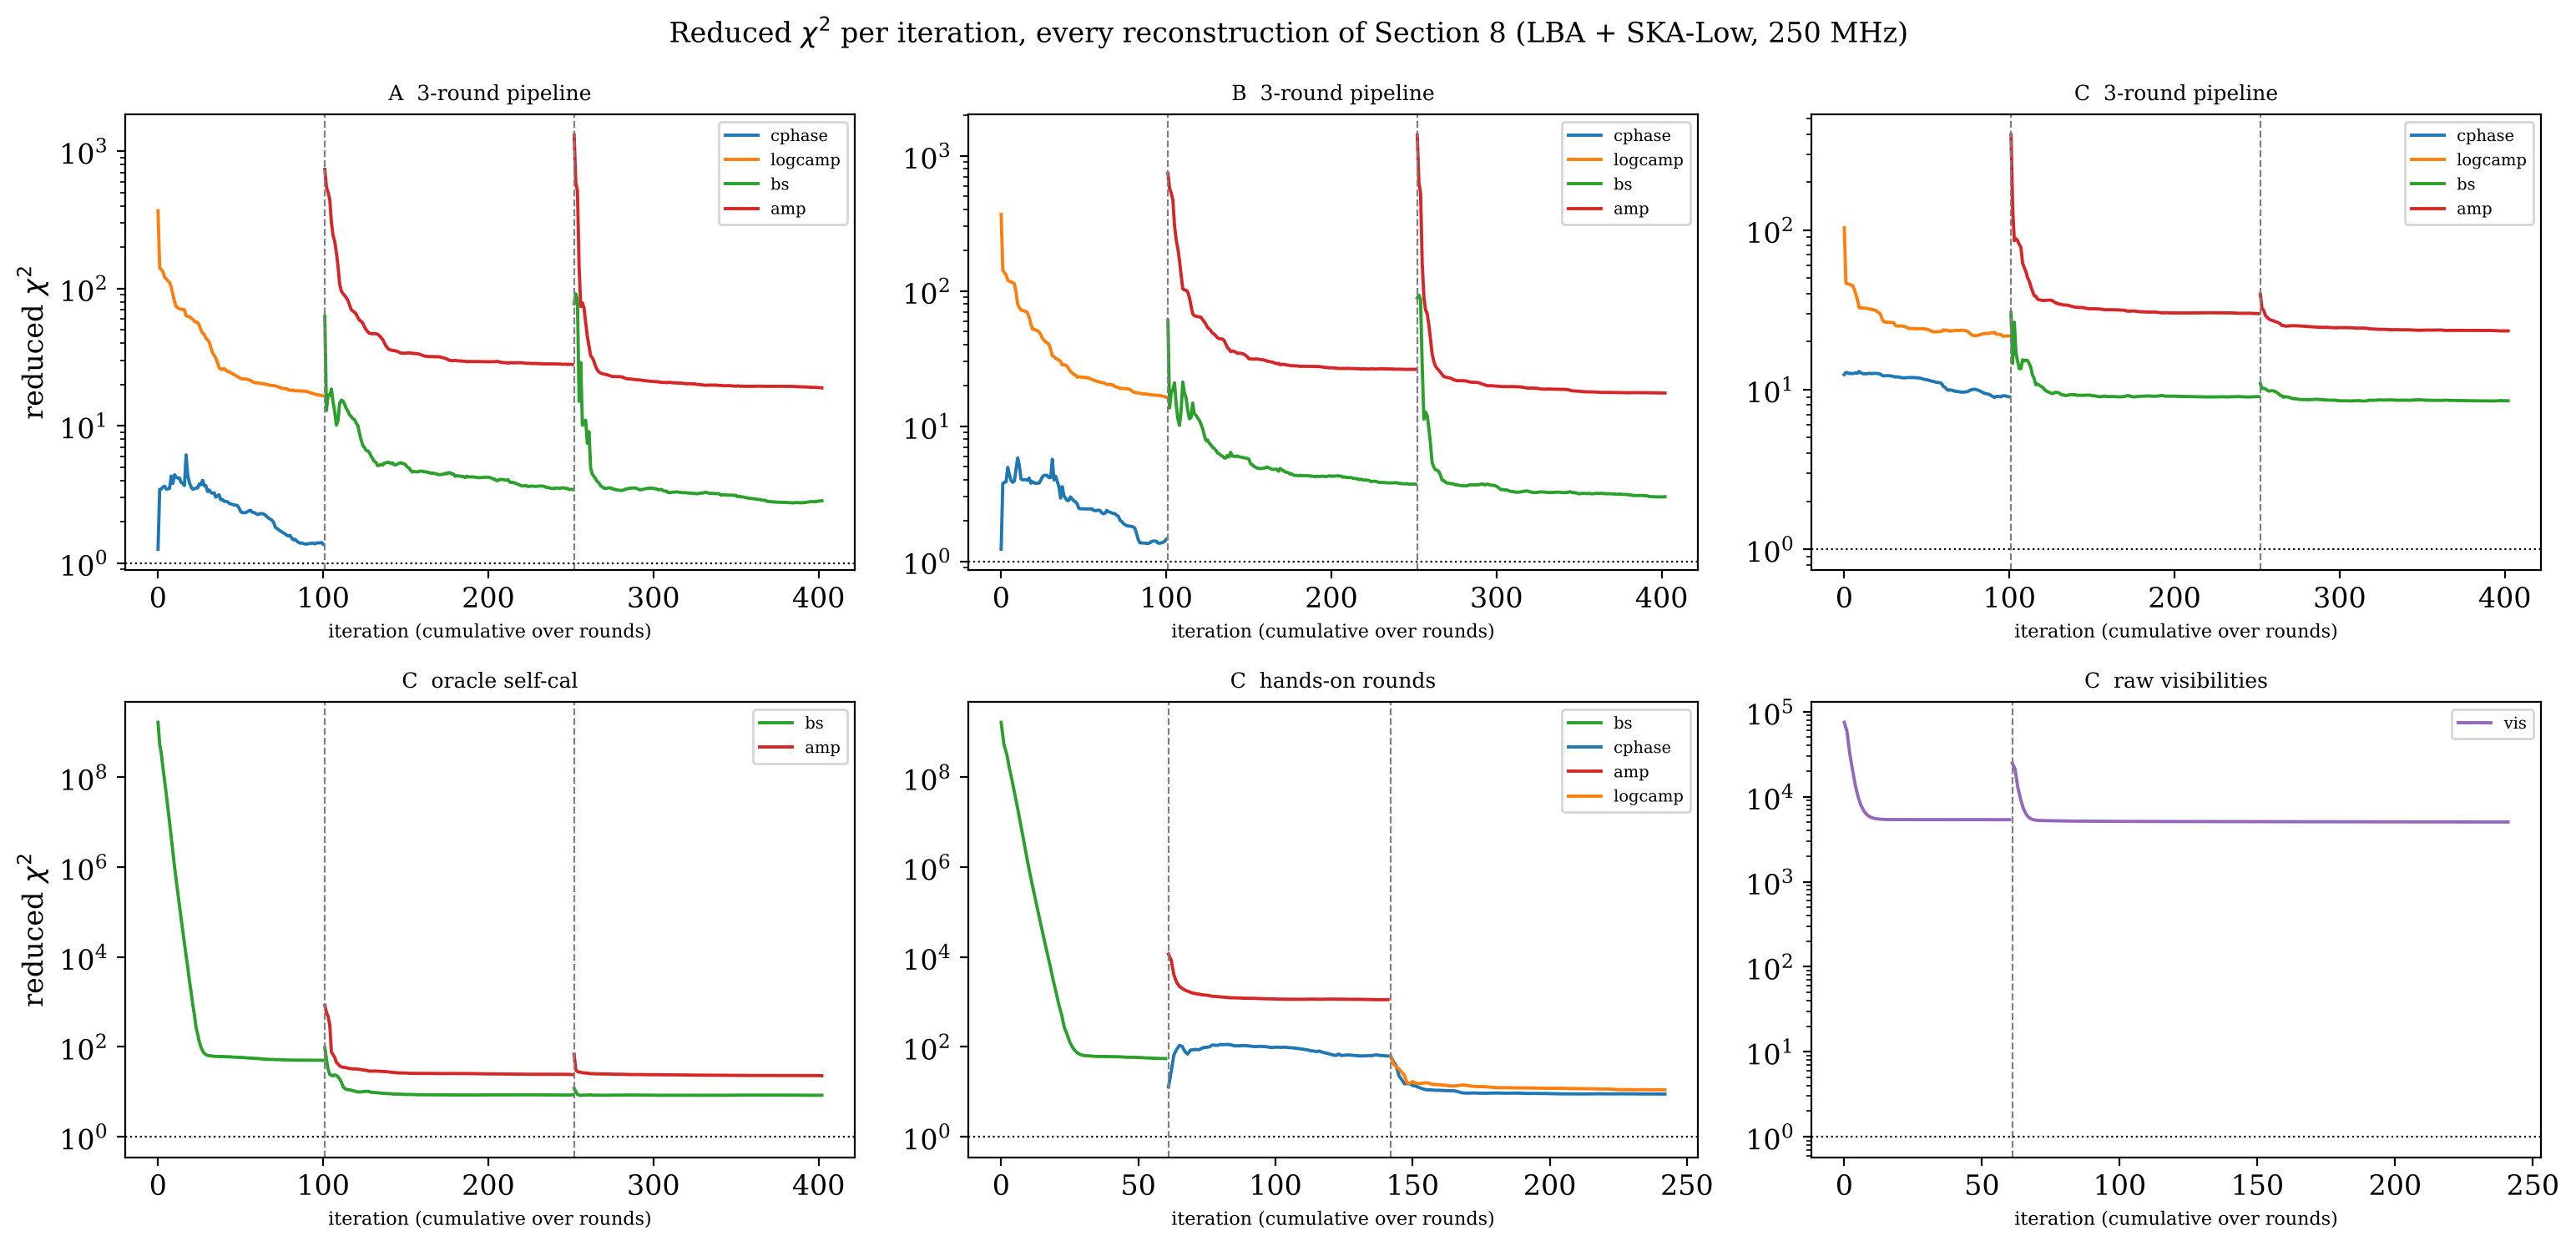

A  3-round pipeline       403 iterations -> final: bs=2.83, amp=18.85
B  3-round pipeline       403 iterations -> final: bs=3.00, amp=17.59
C  3-round pipeline       403 iterations -> final: bs=8.51, amp=23.35
C  oracle self-cal        403 iterations -> final: bs=8.39, amp=22.78
C  hands-on rounds        243 iterations -> final: cphase=8.92, logcamp=11.08
C  raw visibilities       242 iterations -> final: vis=5048.47


In [15]:
plot_chi2_histories(hist, '05b_chi2_convergence_all_reconstructions',
                    r'Reduced $\chi^2$ per iteration, every reconstruction of Section 8 (LBA + SKA-Low, 250 MHz)', ncols=3)
for k, h in hist.items():
    last = h[-1]
    print(f"{k:24s} {len(h):4d} iterations -> final: " + ', '.join(f"{t}={last[t]:.2f}" for t in CHI2_COLORS if t in last))

## 10. Comparison of imaging strategies

To place `pipeline_3rounds` between a calibration-free baseline and a best case, three strategies are run on the same datasets (all with the same prior, final restoring beam and regularizer weights):

* **Closures only (no self-cal):** three rounds on `cphase` and `logcamp` only. It needs no calibration at all.
* **`pipeline_3rounds`:** the pipeline of Section 8, with iterative self-calibration to its own images.
* **Oracle self-cal (reference):** the same structure self-calibrating to the true model.

The difference between the pipeline and the oracle is the cost of not knowing the source; the difference with the closures-only baseline shows what the self-calibration steps add under each scenario.

pipeline                         |  nrmse A      B      C |  nxcorr A      B      C
Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Closures only (no self-cal)      |     0.04   0.05   0.15 |      1.00   1.00   0.99
Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


Initializing imager data products . . .
Using pre-computed cphase table in cphase chi^2!
Using pre-computed log closure amplitude table in log closure amplitude chi^2!


pipeline_3rounds                 |     0.20   0.21   0.12 |      1.00   1.00   0.99
Initializing imager data products . . .
Using pre-computed bispectrum table in cphase chi^2!


Initializing imager data products . . .
Using pre-computed bispectrum table in cphase chi^2!


Initializing imager data products . . .
Using pre-computed bispectrum table in cphase chi^2!


Oracle self-cal (reference)      |     0.02   0.03   0.11 |      1.00   1.00   0.99


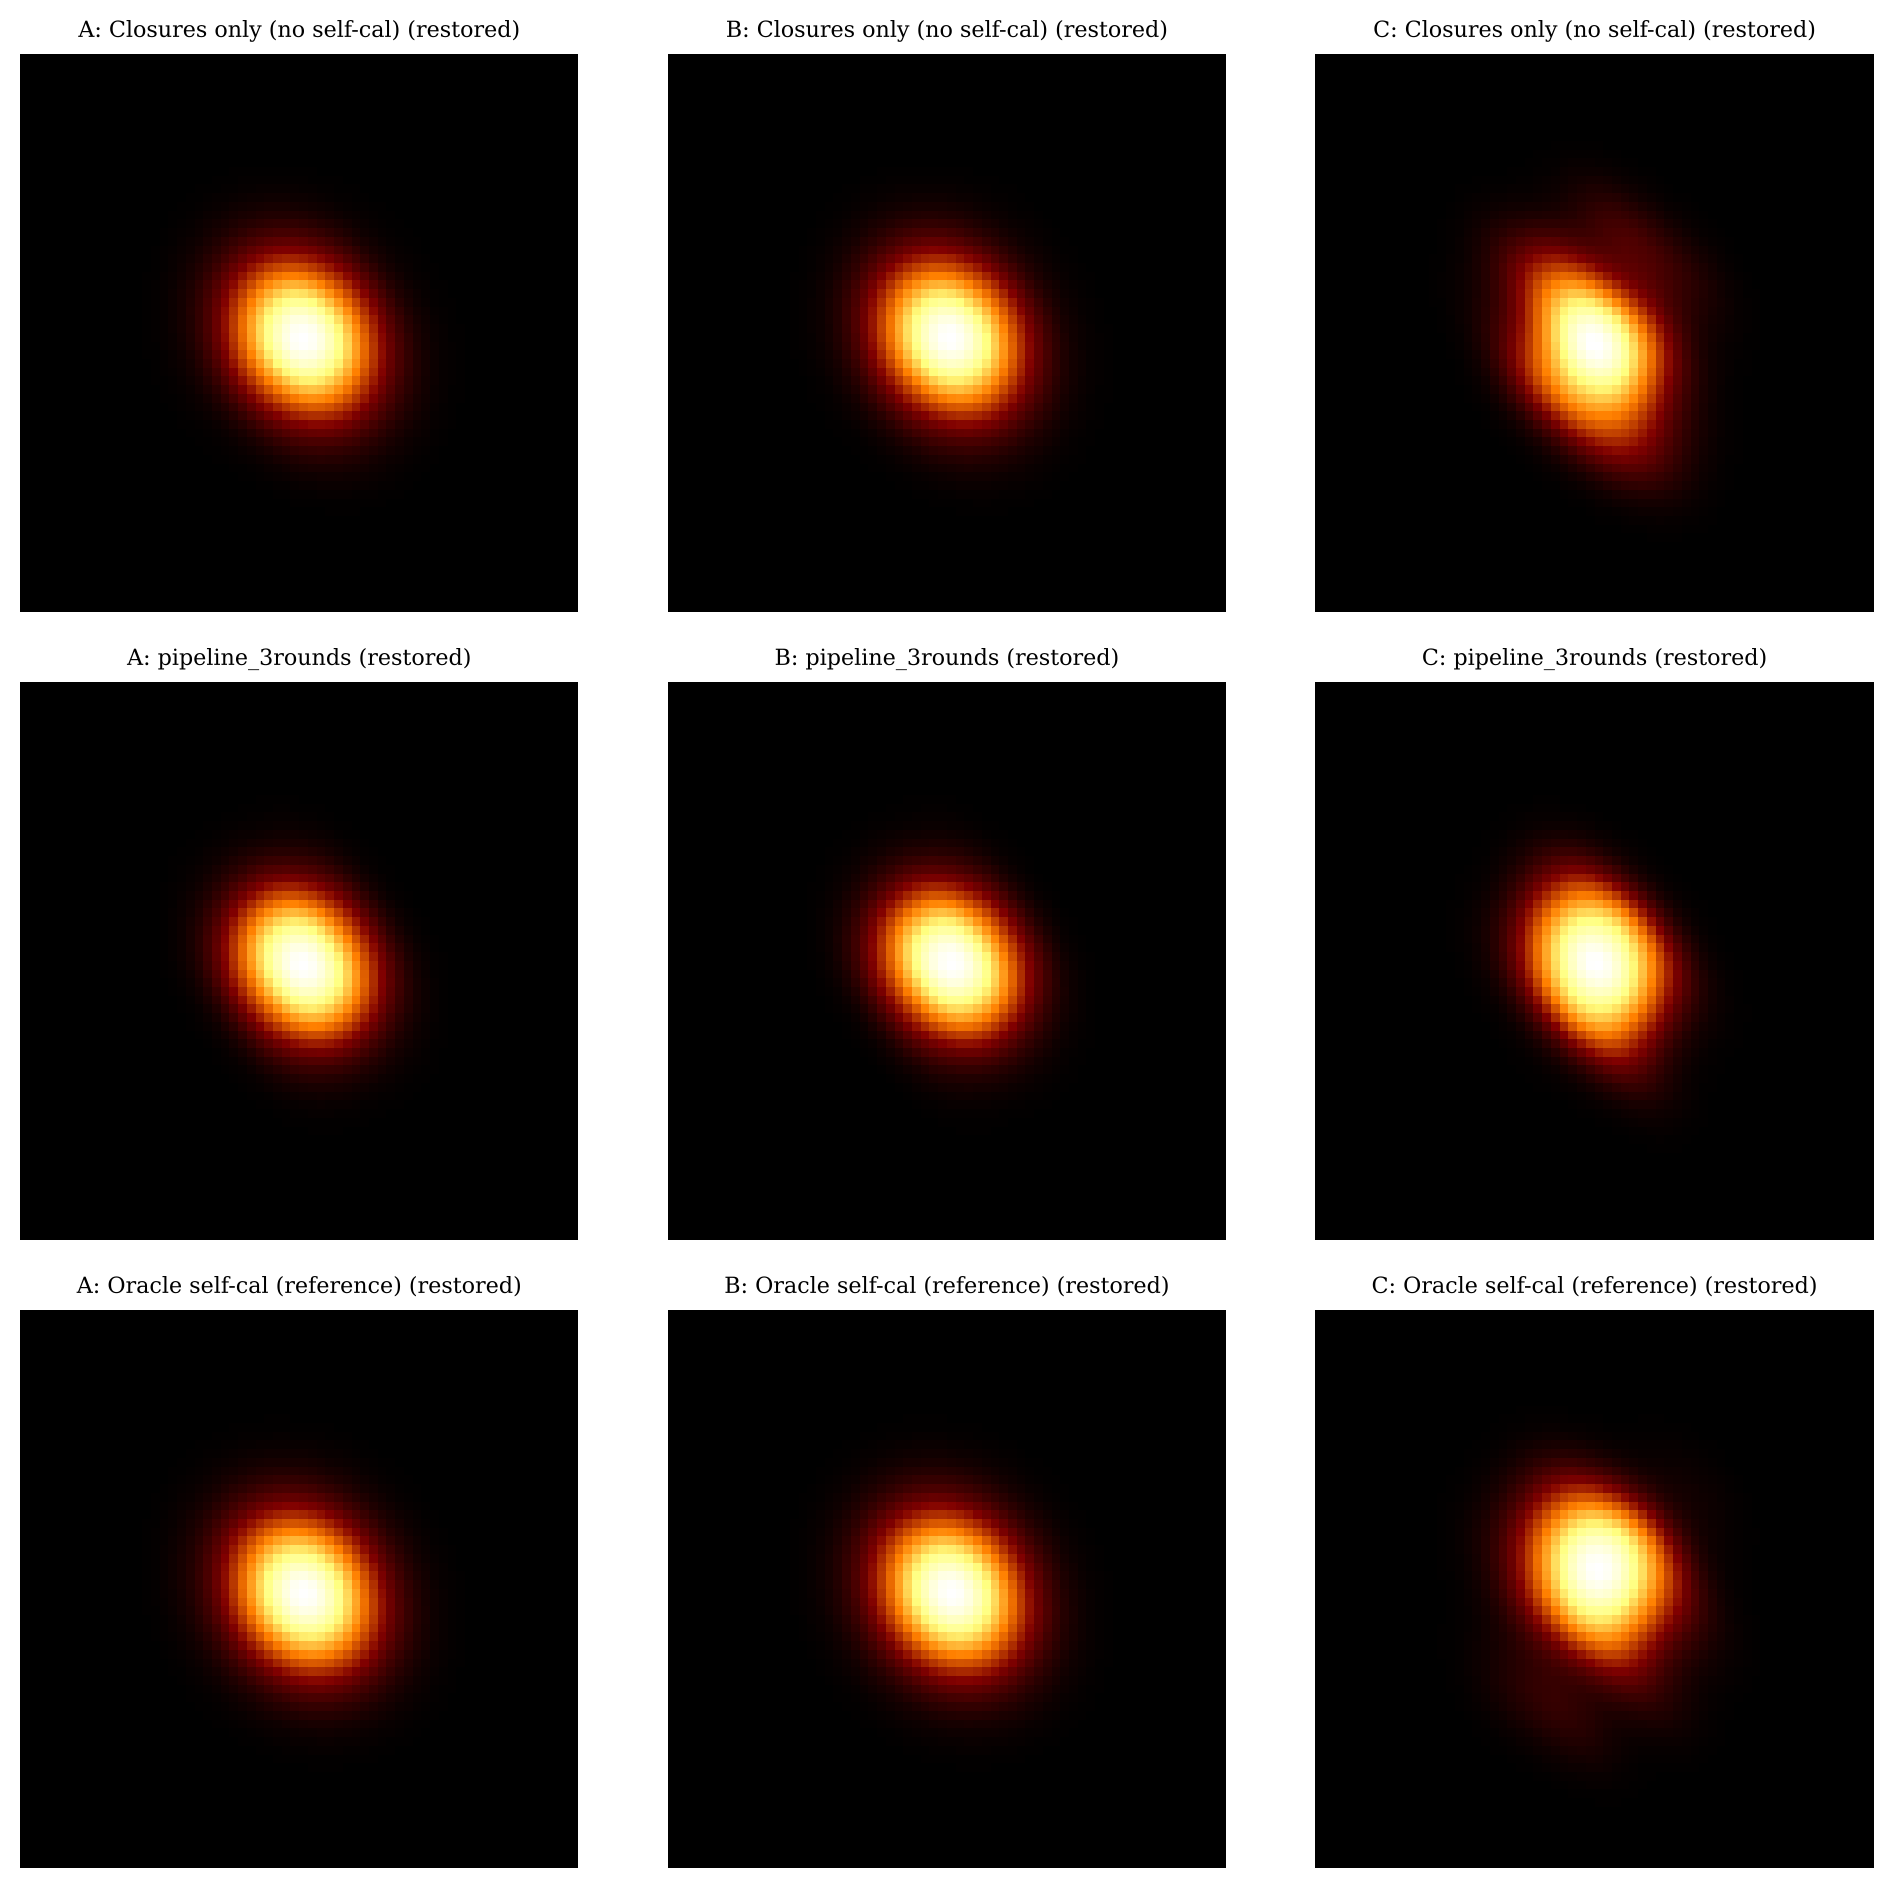

In [16]:
candidates = {
 'Closures only (no self-cal)': [
     {'data_term': CL, 'reg_term': {'simple': w_simple, **FM}, 'maxit': 100},
     {'data_term': CL, 'reg_term': {'tv': w_tv, **FM},      'maxit': 150, 'blur_frac': 1.0},
     {'data_term': CL, 'reg_term': {'tv': w_tv, **FM},      'maxit': 150, 'blur_frac': 0.5}],
 'pipeline_3rounds':           pipeline_3rounds,
 'Oracle self-cal (reference)':            pipeline_oracle,
}
datasets = {'A': obs_A, 'B': obs_B, 'C': obs_C}

study = {}; study_rows = []; study_hist = {}
print(f"{'pipeline':32s} | {'nrmse A':>8s} {'B':>6s} {'C':>6s} | {'nxcorr A':>9s} {'B':>6s} {'C':>6s}")
for name, rounds in candidates.items():
    nr, xc = {}, {}
    for sc_name, o in datasets.items():
        study_hist[(name, sc_name)] = []
        im = run_pipeline(o, prior, zbl, rounds, model=im_src, final_beam=beam_params, history=study_hist[(name, sc_name)])
        study[(name, sc_name)] = im
        xc[sc_name], nr[sc_name] = fidelity(im)
        study_rows.append((name, sc_name, nr[sc_name], xc[sc_name]))
    print(f"{name:32s} | {nr['A']:8.2f} {nr['B']:6.2f} {nr['C']:6.2f} | {xc['A']:9.2f} {xc['B']:6.2f} {xc['C']:6.2f}")

fig, ax = plt.subplots(len(candidates), 3, figsize=(10, 3.2*len(candidates)))
for r, name in enumerate(candidates):
    for c_, sc_name in enumerate('ABC'):
        im = study[(name, sc_name)]
        ax[r, c_].imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot'); ax[r, c_].axis('off')
        ax[r, c_].set_title(f'{sc_name}: {name} (restored)', fontsize=8)
plt.tight_layout(); save_fig(fig, '06_imaging_strategies_comparison'); plt.show()

**Convergence of the imaging strategies.** Reduced $\chi^2$ per iteration of every run of the comparison above (rows: strategy; columns: scenario A, B, C; LBA + SKA-Low). The closures-only strategy fits `cphase` and `logcamp` in all three rounds; the other two switch to `bs` and `amp` on self-calibrated data after round 1.

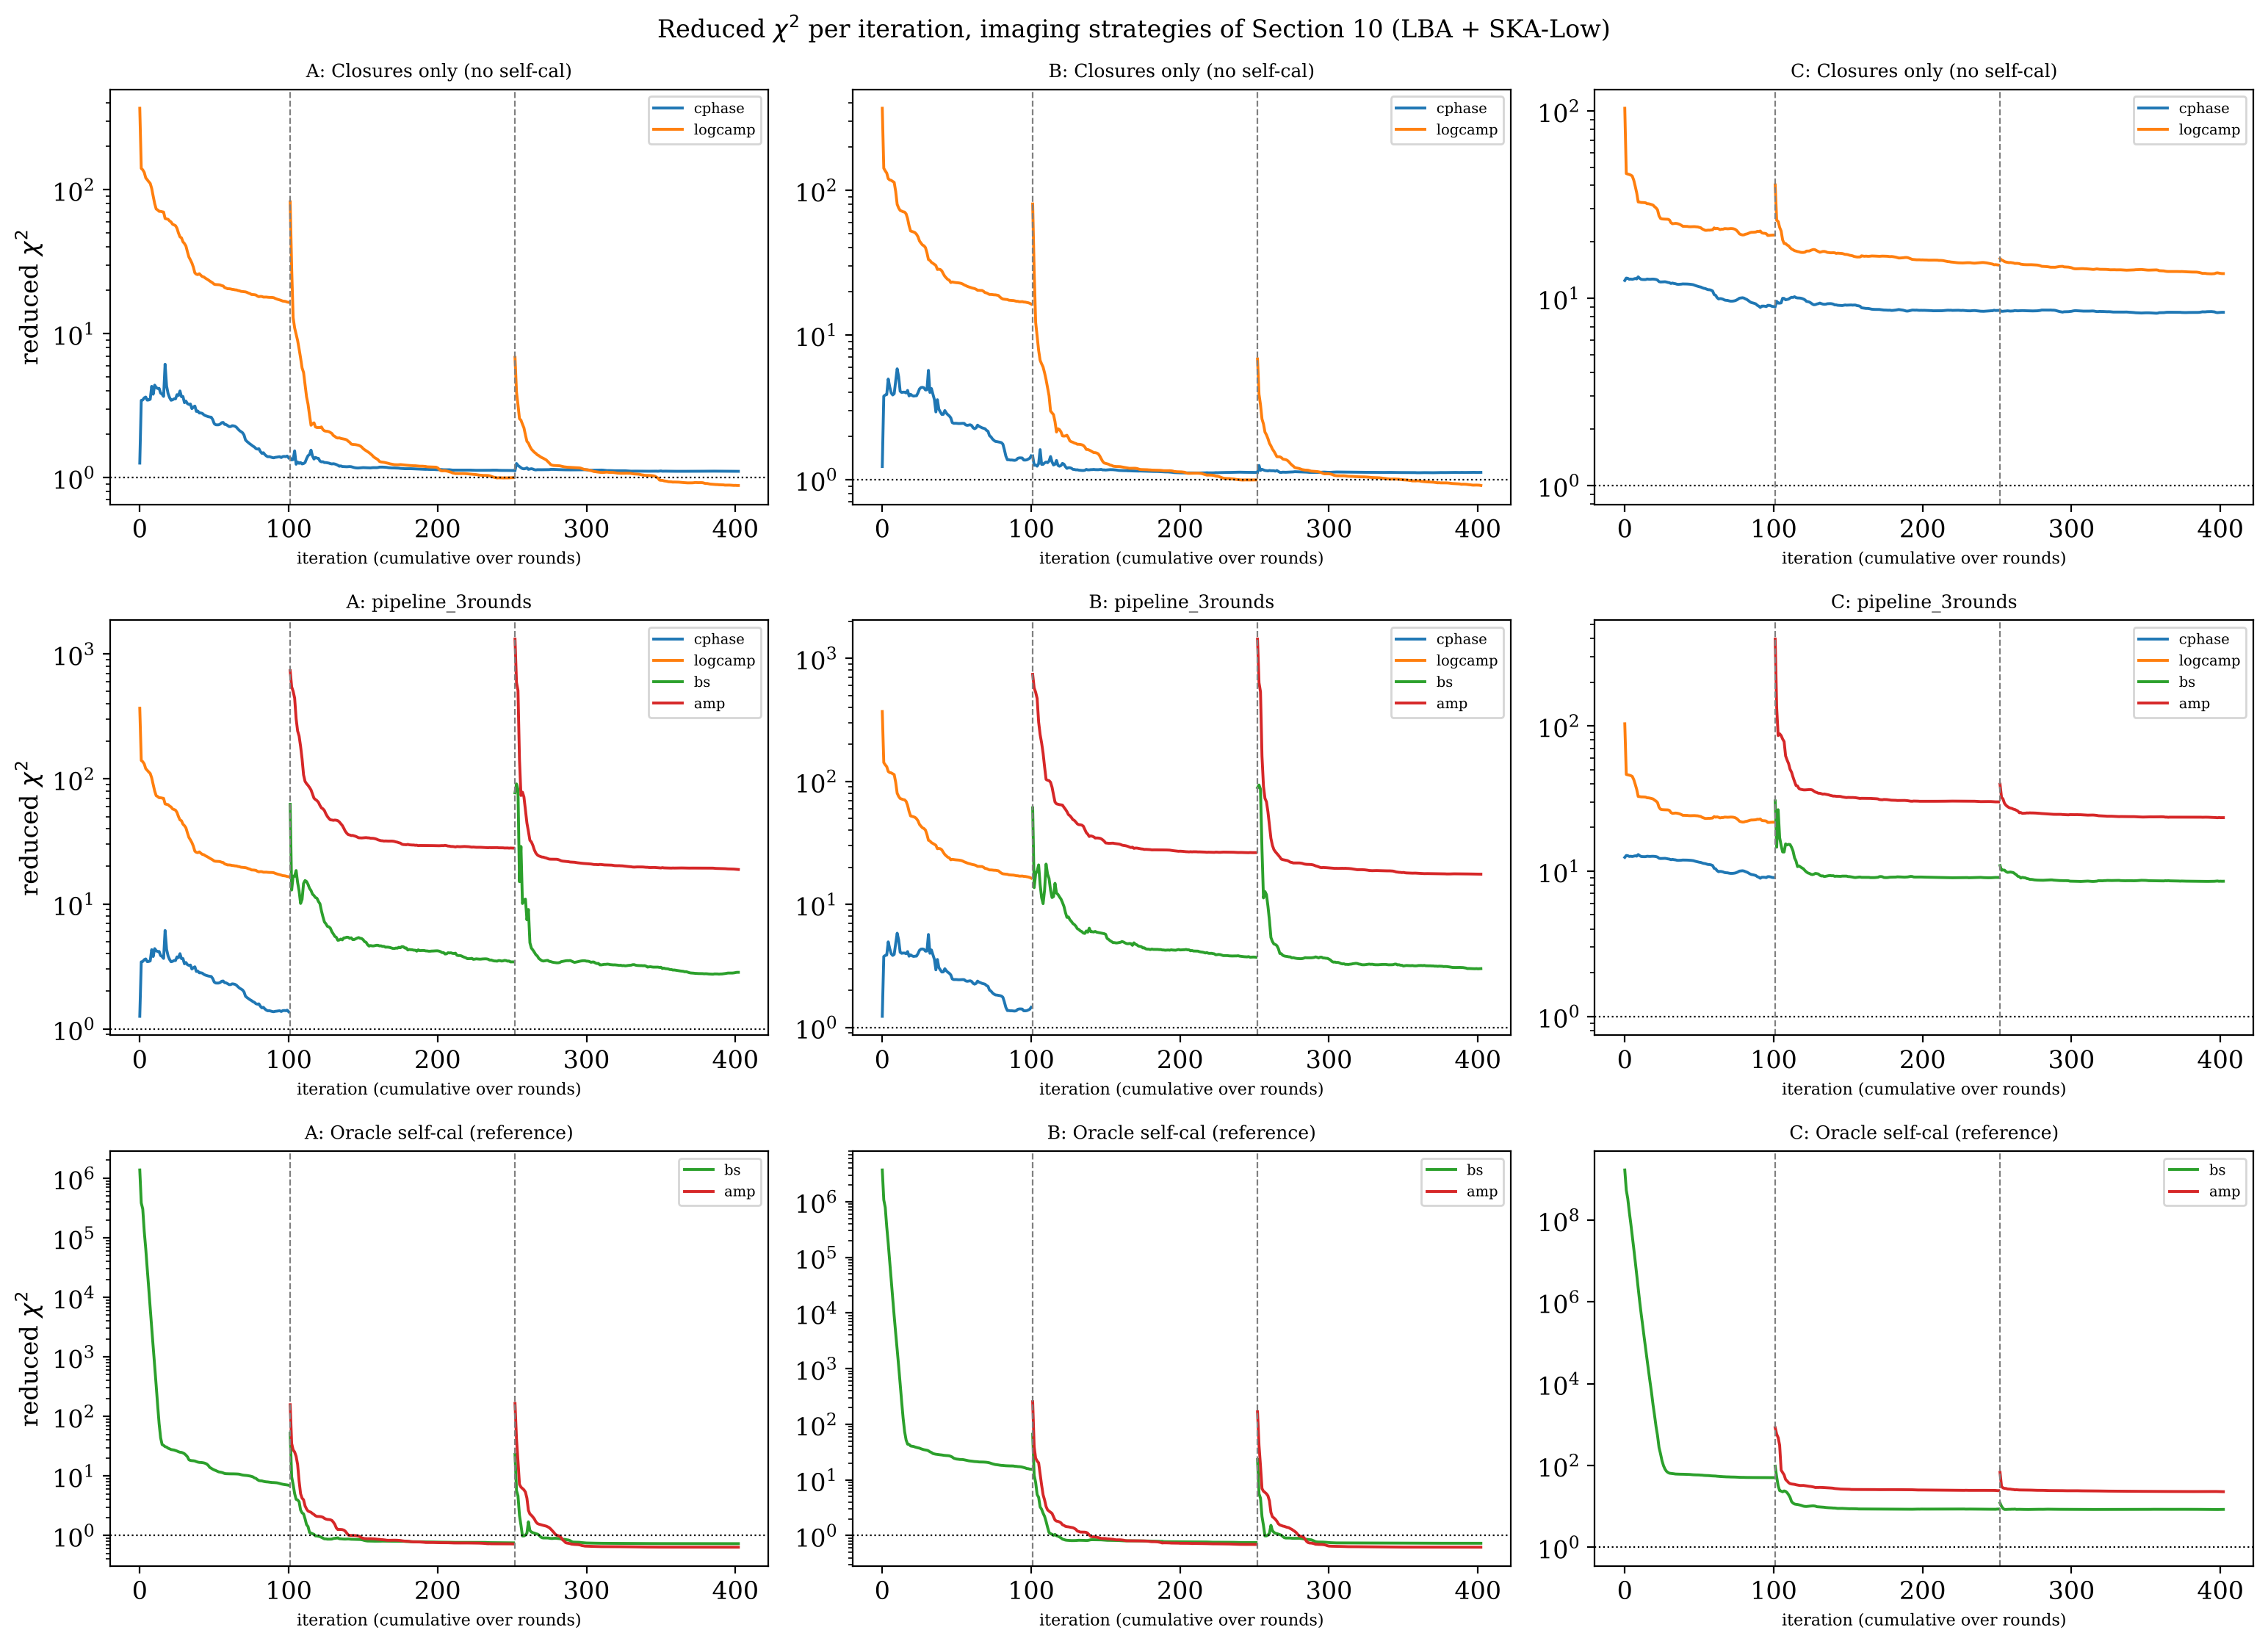

In [17]:
plot_chi2_histories({k: study_hist[k] for k in study}, '06b_chi2_convergence_imaging_strategies',
                    r'Reduced $\chi^2$ per iteration, imaging strategies of Section 10 (LBA + SKA-Low)', ncols=3)

## 11. Self-calibration to the final images: how well do the closures work?

This added case asks a practical question: **if the images obtained above are used as self-calibration models, how good are the calibrated visibilities?** A closure-based image that is right up to the resolution of the array should calibrate the data almost as well as the true source does.

For each scenario, the **raw** data are self-calibrated (amplitude and phase, one gain per station and scan, `self_cal(..., method='both', scan_solutions=True)`) to two models:

1. the **closures-only image** of Section 10 (`cphase` + `logcamp` only, no calibration at any stage): a direct test of what the closure quantities alone recover;
2. the **final image of `pipeline_3rounds`** (Section 8): the last image produced by the pipeline (closures first, then iterative self-calibration).

The models are the *unrestored* images (as in any self-calibration loop). Closure quantities do not fix the absolute position of the source, and a shift of the model is a pure antenna-based phase gradient that self-calibration would transfer to the data, so each model is first shifted (sub-pixel) to the position of the true source. This only removes the unknown absolute position; it does not change anything the closures measured.

The calibrated visibilities are then compared, baseline by baseline, with the **noise-free visibilities of the true source** (the reference observation of Section 3, same schedule):

* **reduced χ² against the truth**, $\langle |V_\mathrm{cal}-V_\mathrm{true}|^2/\sigma^2\rangle/2$: ≈ 1 means the calibrated data differ from the true visibilities only by thermal noise;
* **median amplitude error** [%] and **median phase error** [deg] on the baselines with SNR > 5.

The same numbers are given for the raw data (no calibration) and for the **oracle** calibration (self-calibration to the true model, Section 7; for scenario A, which has no gain errors, the oracle is the data themselves). Finally, each set of calibrated visibilities is **imaged** with the raw-visibility recipe of Section 8 (`vis_rounds`, starting from the same prior), recording the χ² of every iteration, and the images are scored with the same metrics. All of this is done with the **LBA + SKA-Low** array. This cell runs 6 self-calibrations and 6 reconstructions.

Initializing imager data products . . .


Initializing imager data products . . .


  scenario A done (27 s)


Initializing imager data products . . .


Initializing imager data products . . .


  scenario B done (57 s)


Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


Warning! Specified flux is < 80% of maximum visibility amplitude!
Initializing imager data products . . .


  scenario C done (88 s)

sc.  visibilities                                model shift  chi2 vs truth  amp err [%]  phase err [deg]
A    raw data (no calibration)                                         1.00         1.79             1.05
A    self-cal to closures-only image               1.172 mas          16.27         3.26             0.87
A    self-cal to pipeline_3rounds image            0.435 mas         235.23        11.28             0.86
A    oracle (A: data already calibrated)                               1.00         1.79             1.05
B    raw data (no calibration)                                     34374.67        12.60            90.47
B    self-cal to closures-only image               1.552 mas           8.71         2.44             0.90
B    self-cal to pipeline_3rounds image            1.399 mas         256.77        10.46             0.93
B    oracle (true model)                                               0.65         1.38             0.86
C    raw data (no ca

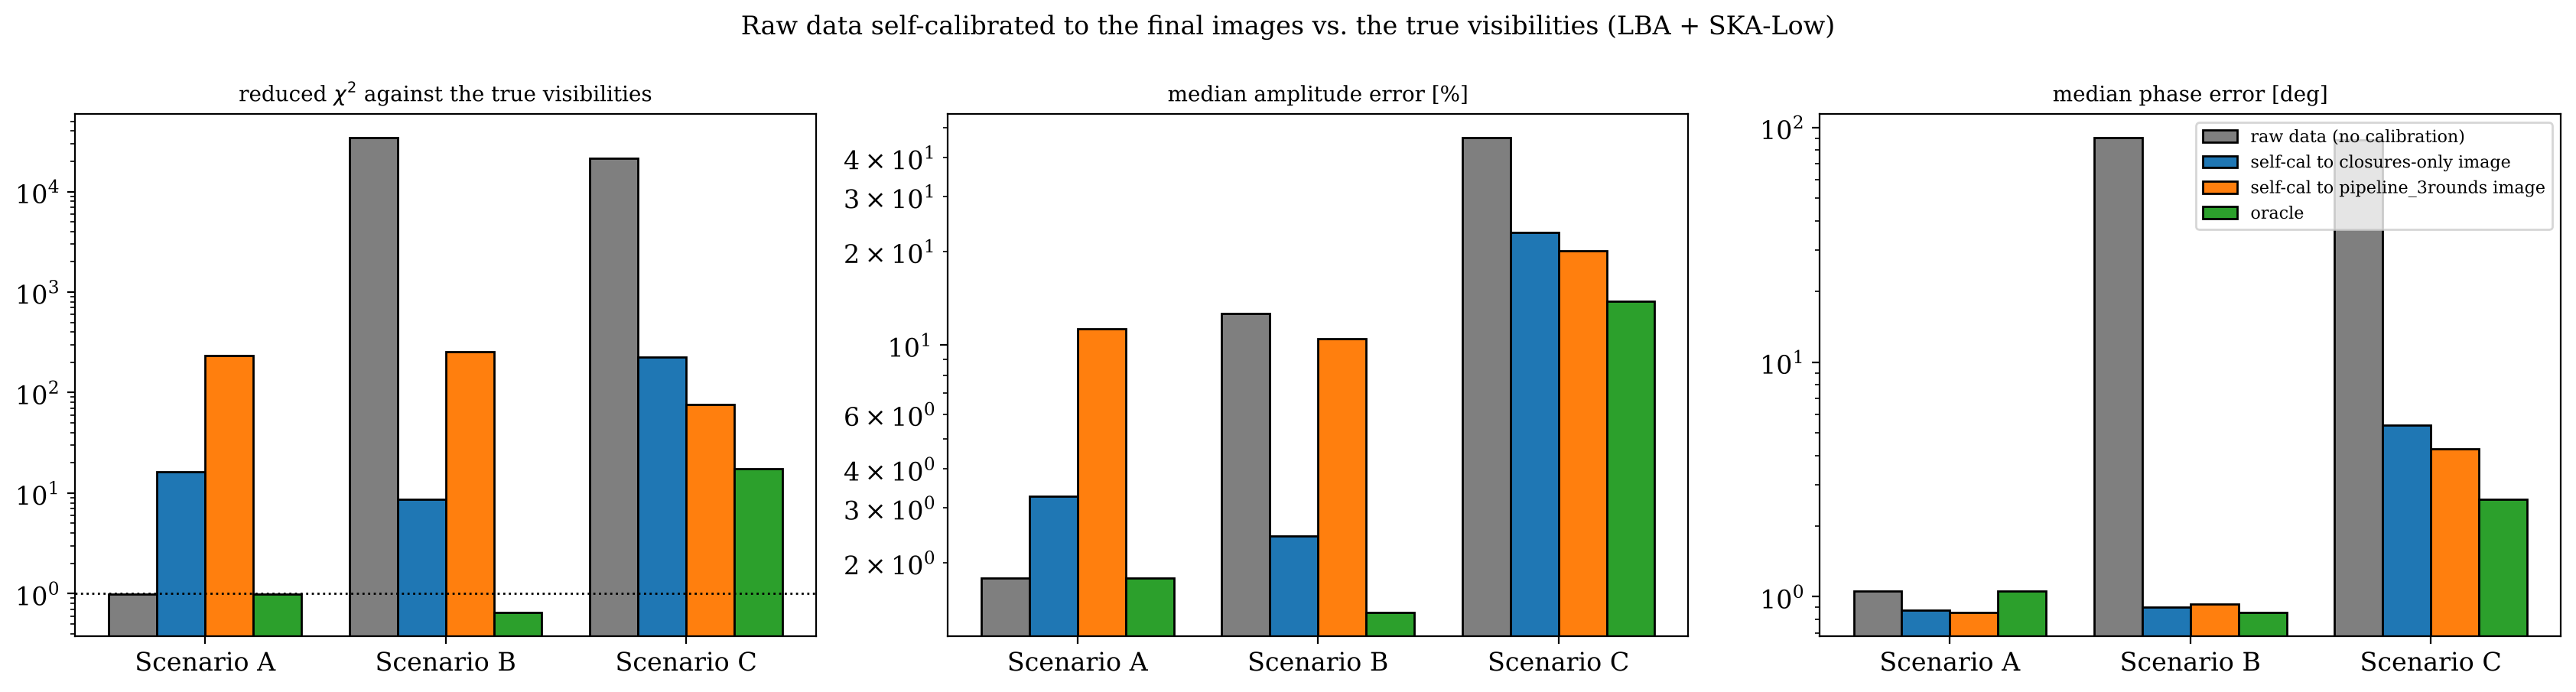

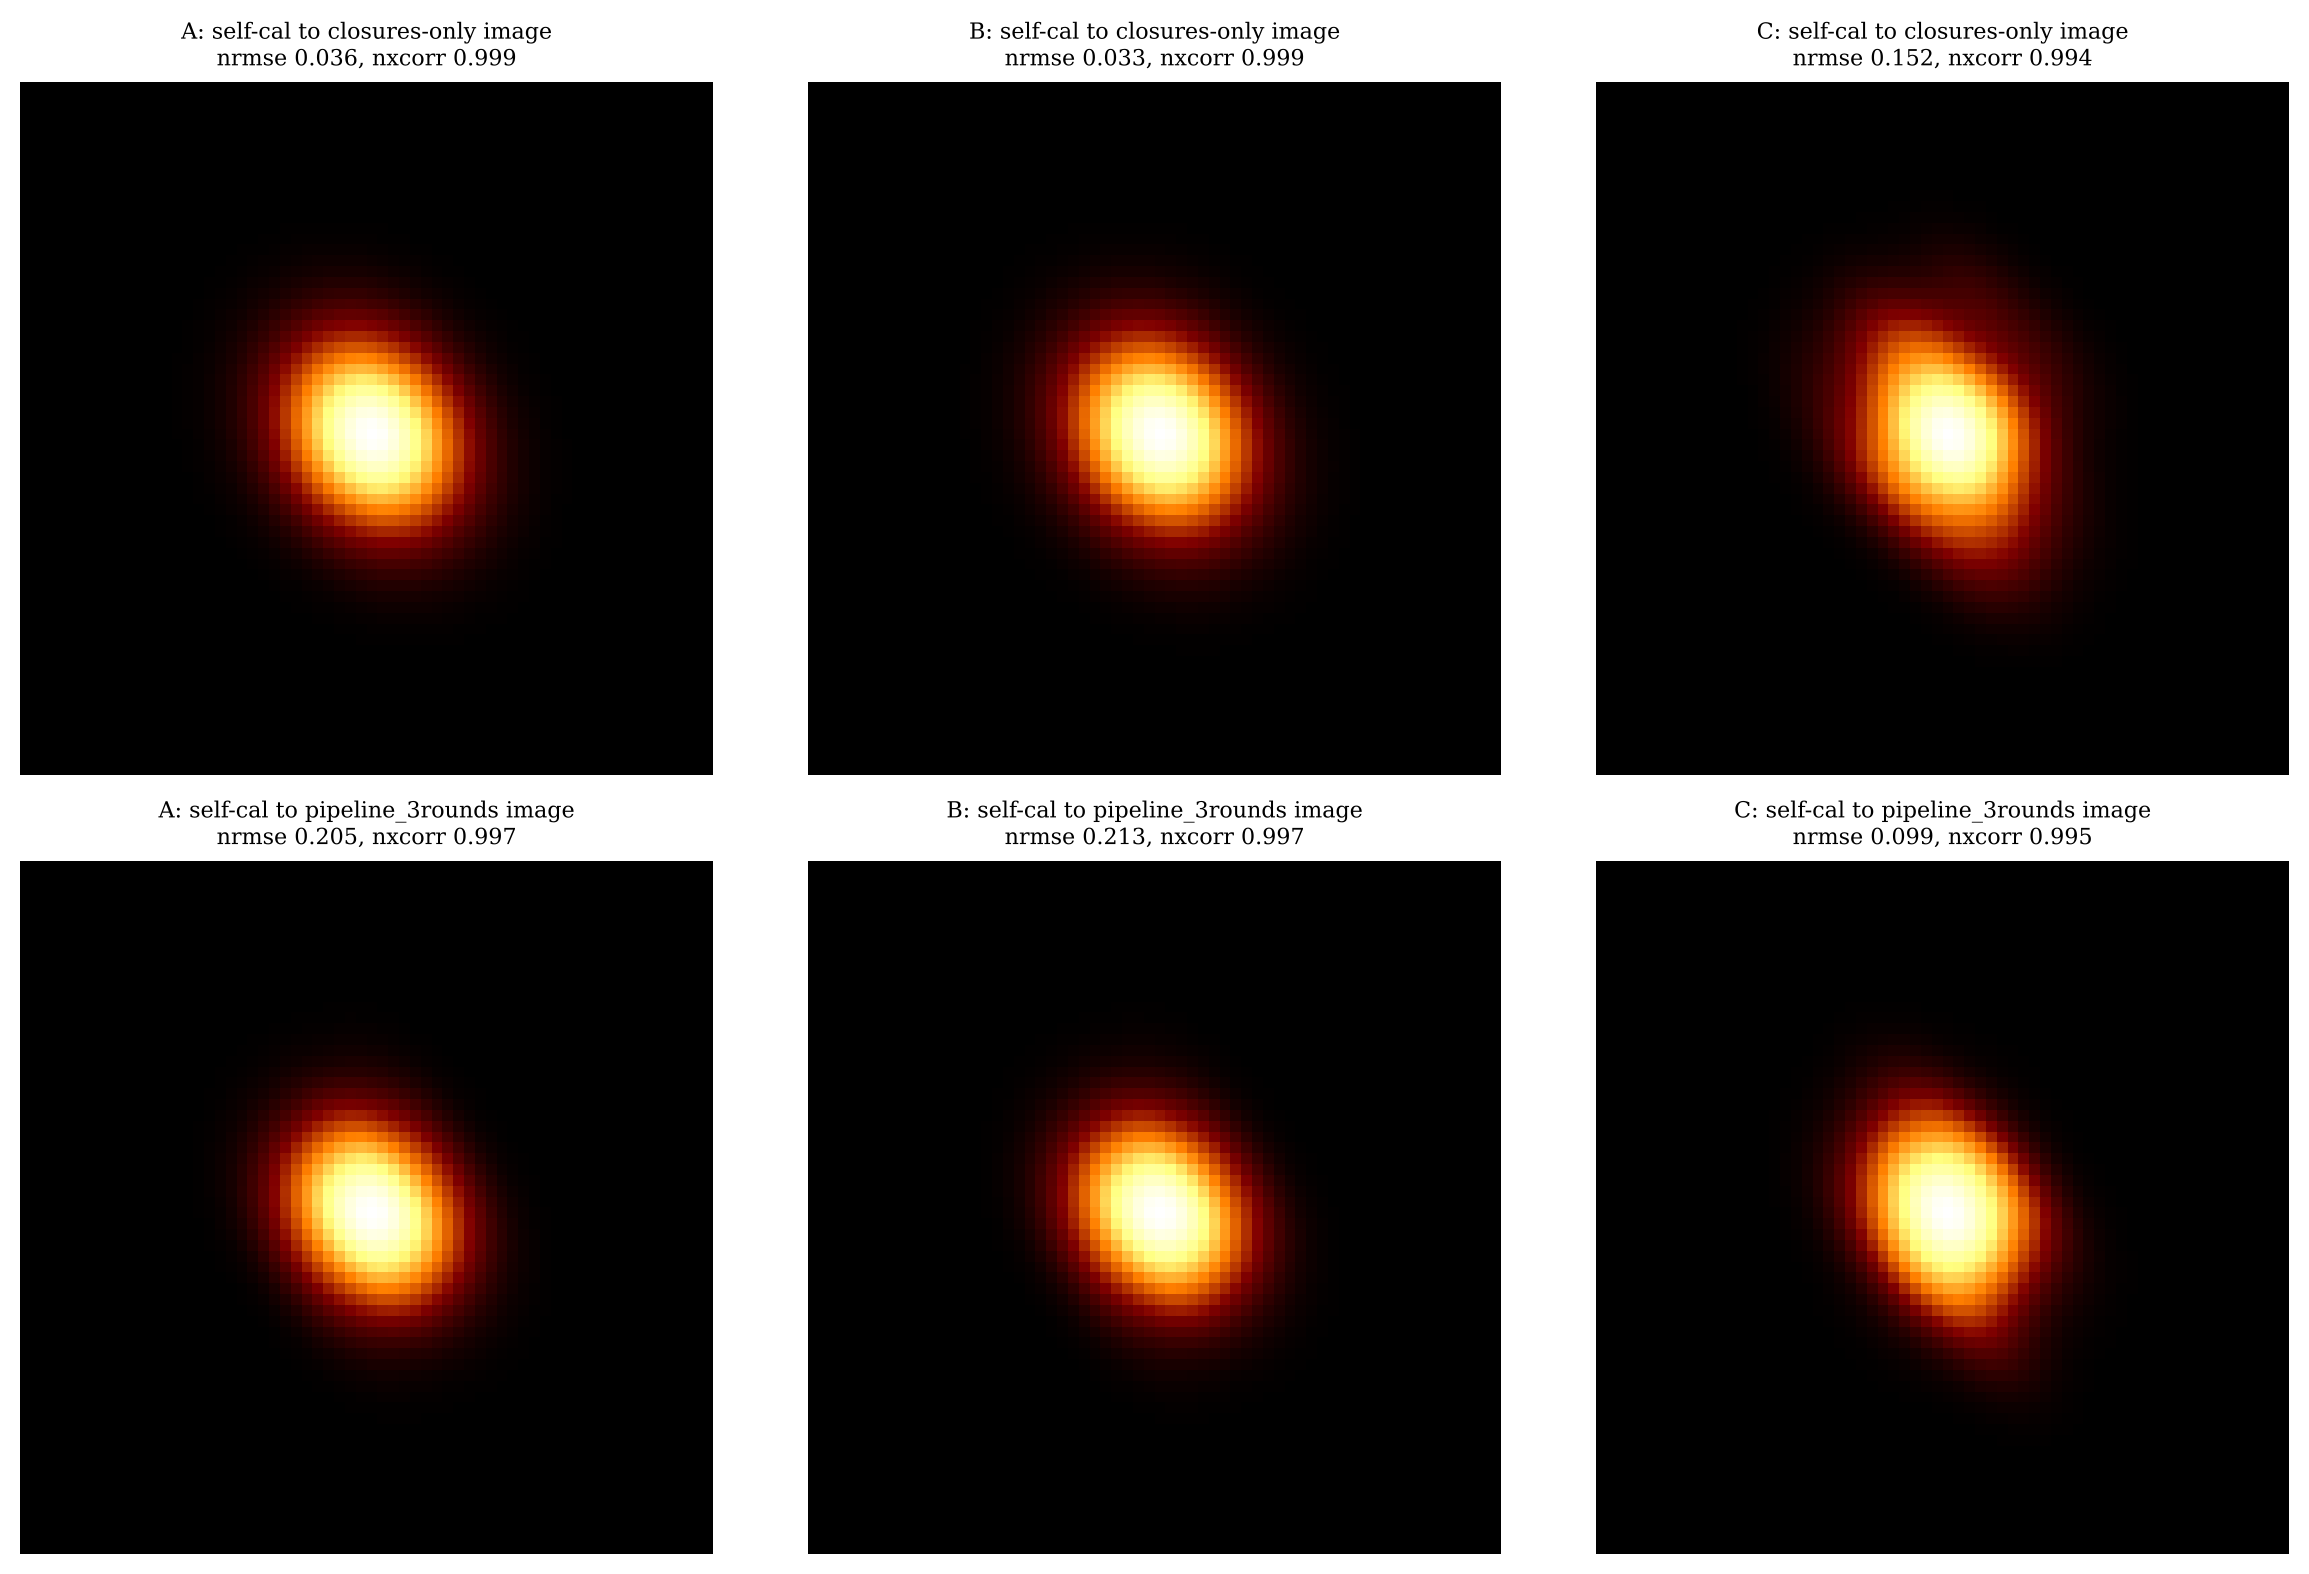

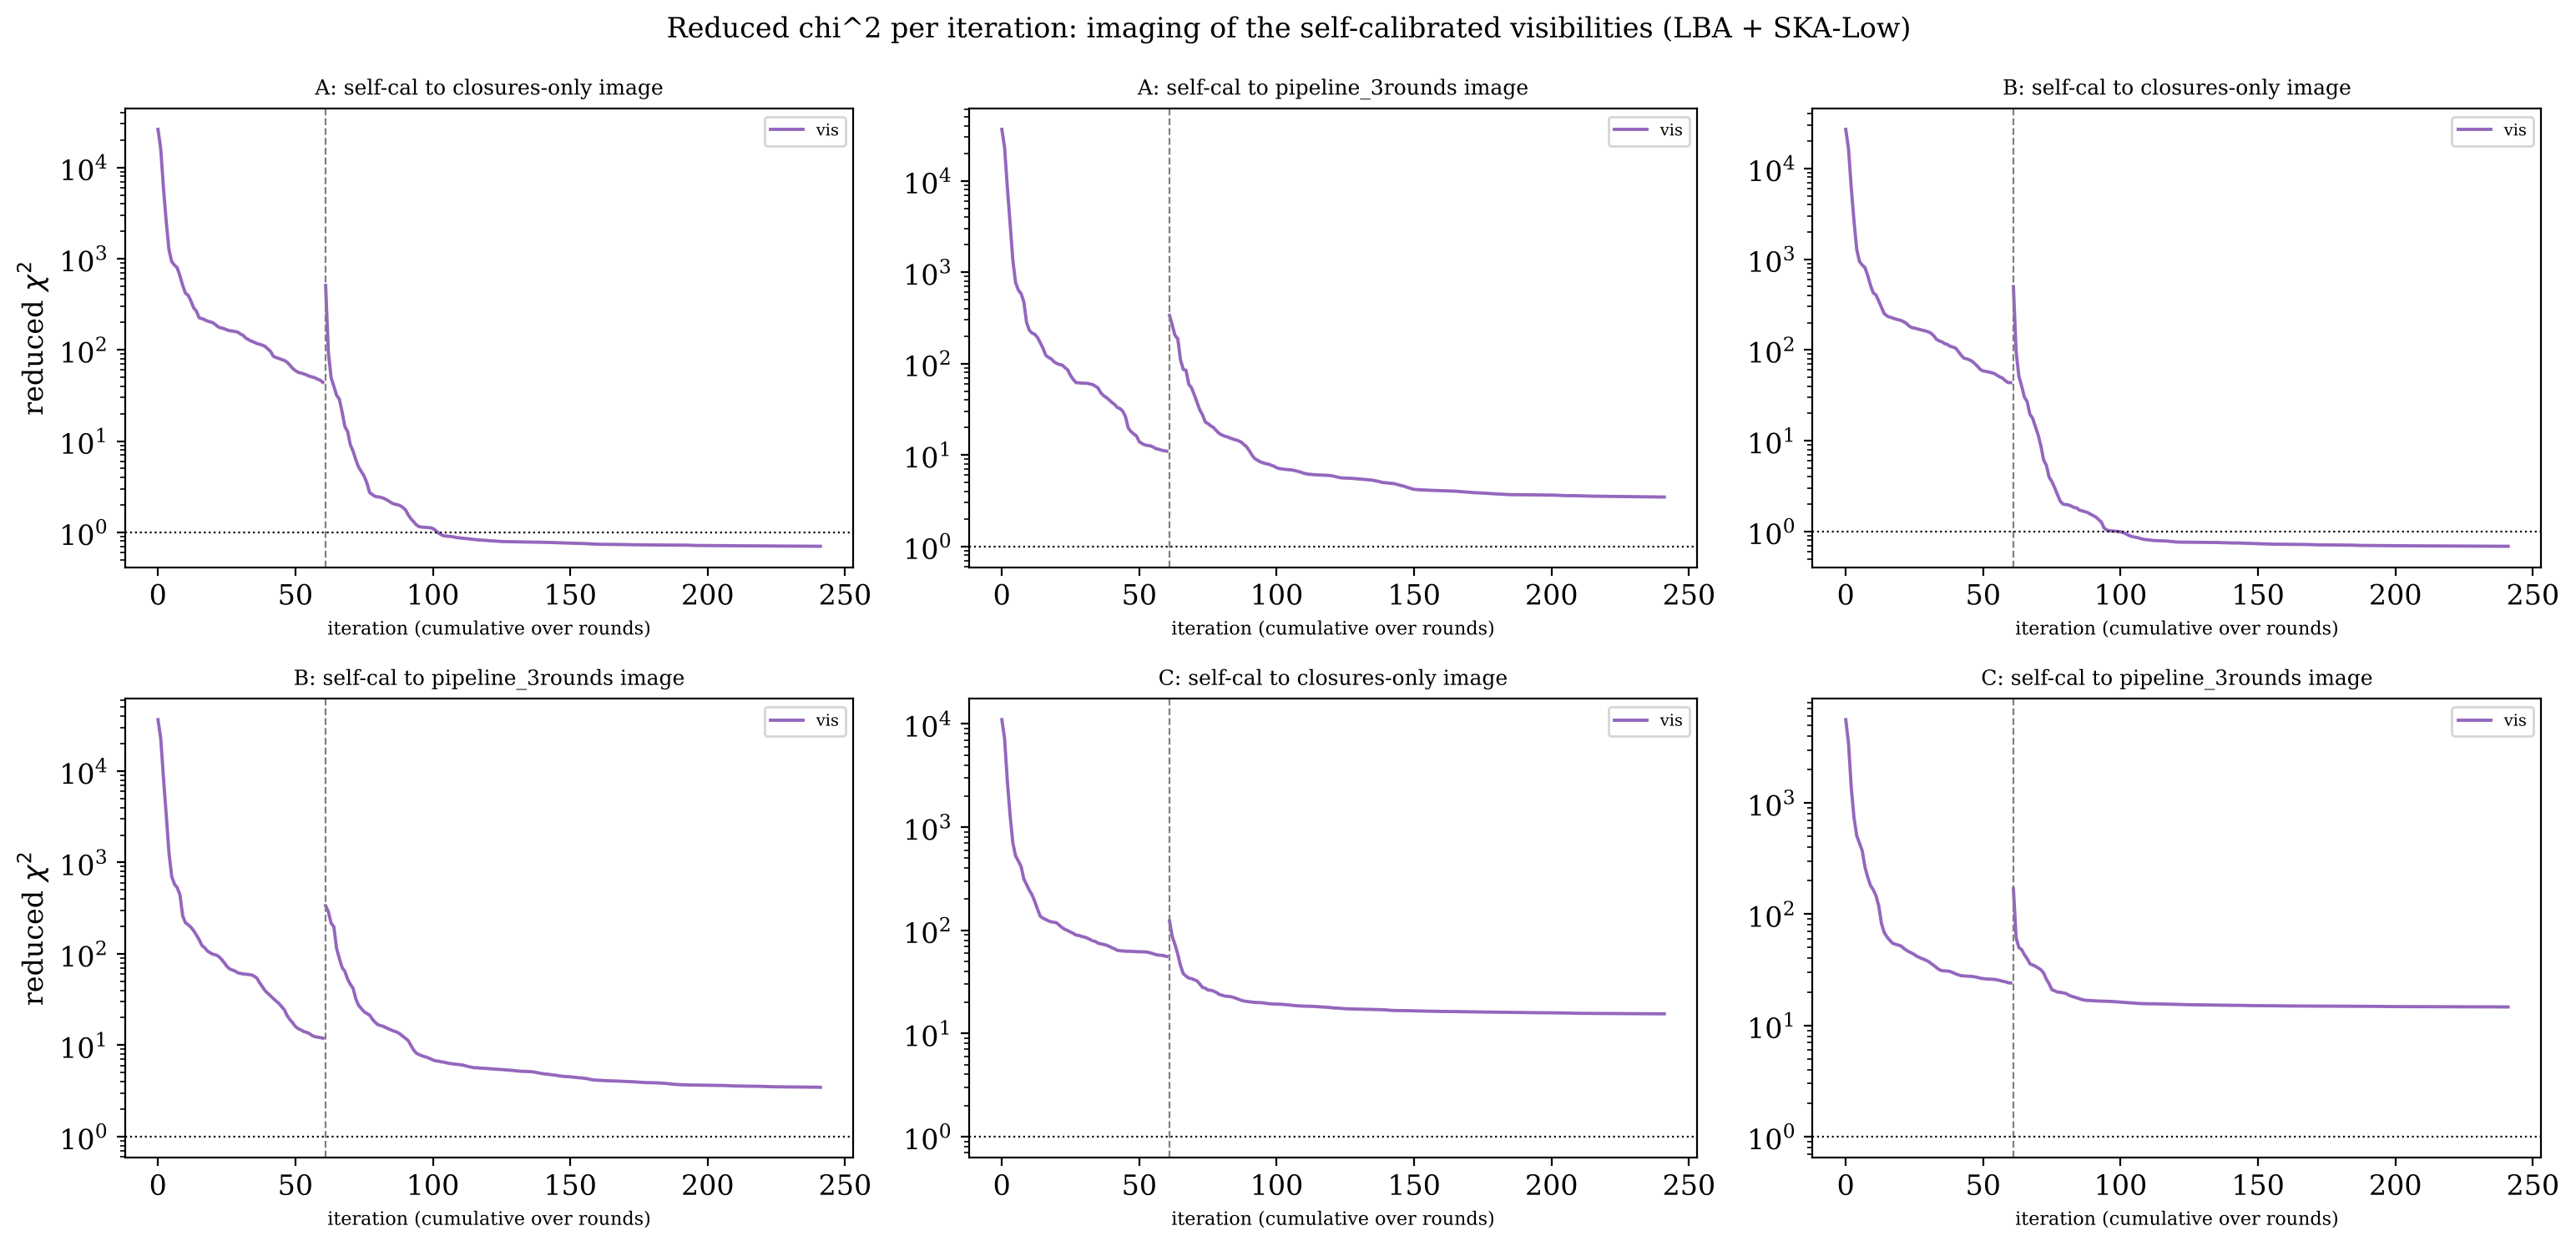

Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


(95 s)


In [18]:
from scipy import ndimage

def align_subpixel(im_model, im_truth):
    # Shift im_model (sub-pixel, Fourier shift) to the position that maximises its cross-correlation with im_truth.
    a = im_model.imvec.reshape(im_model.ydim, im_model.xdim); b = im_truth.imvec.reshape(im_truth.ydim, im_truth.xdim)
    cc = np.real(np.fft.ifft2(np.fft.fft2(b)*np.conj(np.fft.fft2(a))))
    ny, nx = cc.shape; iy, ix = np.unravel_index(np.argmax(cc), cc.shape)
    parab = lambda m, c, p: 0.5*(m - p)/(m - 2*c + p) if (m - 2*c + p) != 0 else 0.0
    dy = iy + parab(cc[(iy-1) % ny, ix], cc[iy, ix], cc[(iy+1) % ny, ix])
    dx = ix + parab(cc[iy, (ix-1) % nx], cc[iy, ix], cc[iy, (ix+1) % nx])
    dy = dy - ny if dy > ny/2 else dy; dx = dx - nx if dx > nx/2 else dx
    sh = np.clip(np.real(np.fft.ifft2(ndimage.fourier_shift(np.fft.fft2(a), (dy, dx)))), 0, None)
    out = im_model.copy(); out.imvec = (sh*im_model.total_flux()/sh.sum()).ravel()
    return out, np.hypot(dy, dx)*im_model.psize/mas

def vis_errors(o, ref, snr_min=5.0):
    # Calibrated (or raw) visibilities of `o` vs. the noise-free visibilities of `ref` (same schedule).
    key = lambda d: list(zip(np.round(d['time']*3600).astype(int), d['t1'], d['t2']))
    r = dict(zip(key(ref.data), ref.data['vis']))
    kk = key(o.data); m = np.array([k in r for k in kk])
    v, s = o.data['vis'][m], o.data['sigma'][m]
    vt = np.array([r[k] for k, mm in zip(kk, m) if mm])
    hi = np.abs(vt)/s > snr_min
    return (float(np.mean(np.abs(v - vt)**2/s**2)/2),
            float(np.median(np.abs(np.abs(v[hi])/np.abs(vt[hi]) - 1))*100),
            float(np.median(np.abs(np.degrees(np.angle(v[hi]*np.conj(vt[hi])))))))

truth_grid = im_src.regrid_image(fov, npix); truth_grid.imvec *= zbl/truth_grid.total_flux()
models = {'closures-only image': lambda s_: study[('Closures only (no self-cal)', s_)].unrestored,
          'pipeline_3rounds image': lambda s_: recs[f'{s_}  3-round pipeline'].unrestored}
raw_obs = {'A': obs_A, 'B': obs_B, 'C': obs_C}
oracle_obs = {'A': obs_A, 'B': cal_B_oracle, 'C': cal_C_oracle}

sc_cal, sc_recs, sc_hist, sc_rows = {}, {}, {}, []
t_sc = time.time()
for s_ in 'ABC':
    sc_rows.append((s_, 'raw data (no calibration)', np.nan) + vis_errors(raw_obs[s_], obs_ideal))
    for mname, get_model in models.items():
        model, shift = align_subpixel(get_model(s_), truth_grid)
        with contextlib.redirect_stdout(io.StringIO()):
            cal = sc.self_cal(raw_obs[s_], model, method='both', ttype='fast', scan_solutions=True, processes=1)
        sc_cal[(s_, mname)] = cal
        sc_rows.append((s_, f'self-cal to {mname}', shift) + vis_errors(cal, obs_ideal))
        lab = f'{s_}: self-cal to {mname}'
        sc_hist[lab] = []
        sc_recs[lab] = run_rml_imager(cal, prior, zbl, vis_rounds, history=sc_hist[lab]).blur_gauss(beam_params, frac=1.0)
    sc_rows.append((s_, 'oracle (true model)' if s_ != 'A' else 'oracle (A: data already calibrated)', np.nan)
                   + vis_errors(oracle_obs[s_], obs_ideal))
    print(f"  scenario {s_} done ({time.time()-t_sc:.0f} s)")

print(f"\n{'sc.':4s} {'visibilities':42s} {'model shift':>12s} {'chi2 vs truth':>14s} {'amp err [%]':>12s} {'phase err [deg]':>16s}")
for s_, name, shift, chi2_t, a_err, p_err in sc_rows:
    sh = '' if np.isnan(shift) else f'{shift:.3f} mas'
    print(f"{s_:4s} {name:42s} {sh:>12s} {chi2_t:14.2f} {a_err:12.2f} {p_err:16.2f}")

print(f"\nImages of the self-calibrated visibilities (vis_rounds, restored with the fitted dirty beam):")
print(f"{'reconstruction':42s} {'nrmse':>7s} {'nxcorr':>7s} {'flux [Jy]':>10s}")
sc_img_rows = []
for lab, im in sc_recs.items():
    xc, nr = fidelity(im)[:2]
    sc_img_rows.append((lab, nr, xc, im.total_flux()))
    print(f"{lab:42s} {nr:7.3f} {xc:7.3f} {im.total_flux():10.3f}")

# ---- Figure: visibility errors after self-calibration to each model, per scenario
groups = ['raw data (no calibration)', 'self-cal to closures-only image', 'self-cal to pipeline_3rounds image', 'oracle']
gcol = ['tab:gray', 'tab:blue', 'tab:orange', 'tab:green']
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for j, (col, ttl) in enumerate([(3, 'reduced $\\chi^2$ against the true visibilities'), (4, 'median amplitude error [%]'),
                                (5, 'median phase error [deg]')]):
    for g, (gname, c) in enumerate(zip(groups, gcol)):
        vals = [next(r[col] for r in sc_rows if r[0] == s_ and r[1].startswith(gname)) for s_ in 'ABC']
        ax[j].bar(np.arange(3) + (g - 1.5)*0.2, vals, 0.2, color=c, edgecolor='k', label=gname)
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(['Scenario A', 'Scenario B', 'Scenario C'])
    ax[j].set_yscale('log'); ax[j].set_title(ttl, fontsize=10)
ax[0].axhline(1, color='k', ls=':', lw=1)
ax[2].legend(fontsize=8)
fig.suptitle('Raw data self-calibrated to the final images vs. the true visibilities (LBA + SKA-Low)', fontsize=12)
plt.tight_layout(); save_fig(fig, '07_selfcal_to_final_images_visibility_errors'); plt.show()

# ---- Figure: images of the self-calibrated visibilities
h = fov/2/mas
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for r_, mname in enumerate(models):
    for c_, s_ in enumerate('ABC'):
        lab = f'{s_}: self-cal to {mname}'; im = sc_recs[lab]; nr_, xc_ = [(x[1], x[2]) for x in sc_img_rows if x[0] == lab][0]
        ax[r_, c_].imshow(im.imvec.reshape(im.ydim, im.xdim), cmap='afmhot', extent=[h, -h, -h, h]); ax[r_, c_].axis('off')
        ax[r_, c_].set_title(f'{lab}\nnrmse {nr_:.3f}, nxcorr {xc_:.3f}', fontsize=8)
plt.tight_layout(); save_fig(fig, '07b_images_of_selfcalibrated_visibilities'); plt.show()

# ---- Figure: chi^2 at every iteration of the imaging of the self-calibrated visibilities
plot_chi2_histories(sc_hist, '07c_chi2_convergence_selfcalibrated_visibilities',
                    'Reduced chi^2 per iteration: imaging of the self-calibrated visibilities (LBA + SKA-Low)', ncols=3)

# ---- Export: calibrated UVFITS and the tables of this section
for (s_, mname), cal in sc_cal.items():
    tag = 'closures_image' if mname.startswith('closures') else 'pipeline_image'
    try:
        cal.save_uvfits(f'{OUT_DIR}/visibilities/scenario{s_}_selfcal_to_{tag}.uvfits')
        cal.save_txt(f'{OUT_DIR}/visibilities/scenario{s_}_selfcal_to_{tag}.txt')
    except Exception as e:
        print('  [skipped]', s_, tag, e)
import csv
with open(f'{OUT_DIR}/tables/selfcal_to_final_images_visibility_errors.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['scenario', 'visibilities', 'model_shift_mas', 'chi2_vs_true_vis', 'median_amp_err_pct', 'median_phase_err_deg'])
    w.writerows(sc_rows)
with open(f'{OUT_DIR}/tables/selfcal_to_final_images_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'nrmse', 'nxcorr', 'total_flux_Jy']); w.writerows(sc_img_rows)
for lab, im in sc_recs.items():
    fn = lab.replace(': ', '_').replace(' ', '_').replace('-', '')
    try: im.save_fits(f'{OUT_DIR}/images/selfcalvis_{fn}.fits')
    except Exception as e: print('  [skipped]', lab, e)
print(f"({time.time()-t_sc:.0f} s)")

## 12. Discussion of the results

The numbers below are those of the reference run of this notebook (scenario A is reproduced exactly on a re-run; B and C change by a few per cent, because `ehtim` draws their station gains from the Python hash seed). Everything was observed with the **LBA + SKA-Low** (6 LBA antennas + SKA-Low, 7 stations).

**Data.** The 8-h window gives 1850 visibilities on 21 baselines; 17 baselines and 19 of the 35 closure triangles have SNR > 5 (median SNR 27 in A). The baselines to SKA-Low (4.4 Jy) carry the signal, while the LBA–LBA baselines (2000 Jy per antenna) are close to the noise. The restoring beam (fitted dirty beam) is 73 × 43 mas at PA 32°. In scenario C the ionospheric screen decorrelates the visibilities strongly at 250 MHz (1 TECU = 33.8 rad): the mean |Γ| is 0.47, and 0.02 on the worst baseline. The closure-phase rms over all triangles is 53°, 50° and 75° in A, B and C. A and B are equal because antenna-based errors cancel, and the large values come from the low-SNR triangles; the excess in C is the non-closing part of the decorrelation. A pure phase screen without decorrelation changes the closure phases by less than 10⁻¹² deg.

**Images (Sections 8–9).** All three scenarios recover the Gaussian (nxcorr ≥ 0.99). `pipeline_3rounds` gives nrmse 0.20, 0.21 and 0.12 in A, B and C, with dynamic ranges of ~1800, ~1800 and ~830. The raw visibilities of C fail as expected (nrmse 2.6, χ²<sub>vis</sub> ≈ 5000).

**Convergence (χ² per iteration, figures 05 and 05b).** In A and B the closure phases reach χ² ≈ 1.4 in round 1, but the log closure amplitudes are still at ~16 when the 100 iterations of round 1 end, so the round-1 image is not converged. Rounds 2 and 3 fit `bs` to ~3 but the amplitudes only to ~18. In C every term stays higher (cphase ≈ 9, amp ≈ 23), and the oracle reaches the same values (bs 8.4, amp 22.8): the residual is the non-antenna-based decorrelation, which no calibration can remove.

**Strategies (Section 10, figure 06b).** The **closures-only** strategy is the best in A and B (nrmse 0.04 and 0.05, close to the oracle's 0.02 and 0.03). Its χ² history shows why: with two more closure rounds the log closure amplitudes go from 16.5 to 0.9, i.e. the closures are fitted down to the noise. In C the order reverses (closures only 0.15, pipeline 0.12, oracle 0.11), because the closure quantities themselves are corrupted by the decorrelation and the self-calibrated amplitudes help.

**Self-calibration to the final images (Section 11): how well do the closures work?**

| Scenario | Visibilities | χ² vs. true | Amp. error | Phase error |
|---|---|---|---|---|
| A | raw (= oracle) | 1.0 | 1.8 % | 1.0° |
| A | self-cal to closures-only image | 16 | 3.3 % | 0.9° |
| A | self-cal to pipeline image | 235 | 11.3 % | 0.9° |
| B | raw | 34 000 | 12.6 % | 90° |
| B | self-cal to closures-only image | 8.7 | 2.4 % | 0.9° |
| B | self-cal to pipeline image | 257 | 10.5 % | 0.9° |
| B | oracle | 0.65 | 1.4 % | 0.9° |
| C | raw | 22 000 | 46 % | 89° |
| C | self-cal to closures-only image | 224 | 23 % | 5.4° |
| C | self-cal to pipeline image | 76 | 20 % | 4.3° |
| C | oracle | 17 | 14 % | 2.6° |

* **In A and B the closures work very well.** Self-calibrating the raw data of B to the closures-only image removes the 90° phase errors completely (0.9°, the same as the oracle) and brings the amplitude error from 12.6% to 2.4%. Imaging those visibilities converges to χ²<sub>vis</sub> < 1 (figure 07c) and gives nrmse 0.03, as good as the oracle.
* **The phases are right with either model, but the pipeline image has the wrong flux scale.** Self-calibrating to the pipeline image gives the same phase error (0.9°) but ~11% amplitude errors. Self-calibration transfers the model's flux scale to the data, and the vis images made from them have a total flux of 0.78 Jy instead of 1. The cause is the amplitude self-calibration before round 2 of the pipeline, which uses the unconverged round-1 image; with only 7 stations, each gain amplitude is weakly constrained. A longer round 1, or a phase-only first self-calibration (as in the 5 GHz jet notebook), would avoid it.
* **In C the closures are not enough.** The closure-only image is distorted by the non-closing decorrelation (its position is also off by 10 mas). Self-calibration to the pipeline image is better (χ² 76 vs. 224), but neither approaches the oracle, and even the oracle stays at χ² = 17: at 250 MHz the in-band ionospheric decorrelation needs a dispersive fringe fit or ionospheric calibration, not better imaging.

**In short:** with the LBA + SKA-Low at 250 MHz, a Gaussian source under antenna-based errors (A, B) is recovered almost perfectly by the closure quantities alone, and the closure image is an excellent self-calibration model. The weak point of the fixed pipeline is the amplitude self-calibration to an unconverged first image. Under the structured ionospheric errors of C, the limit is set by the decorrelation itself.

## 13. Export everything to a single folder

Collects in one folder (`results_VLBI/`) and in one zip file (`results_VLBI.zip`):
* `visibilities/`: the visibilities of the reference observation and of scenarios A, B, C (and the oracle self-calibrated B and C), each in `.uvfits` and `.txt`;
* `figures/`: every figure of the notebook as `.png`;
* `images/`: the input model and all reconstructions as `.fits`;
* `tables/`: metrics tables, the reduced $\chi^2$ of every reconstruction at every iteration (`chi2_history_all_reconstructions.csv`) and at the end of each round (`chi2_final_per_round.csv`), a table of the regularizers and weights of every pipeline (`pipelines_regularizers.csv/.md`, with the chosen one marked), SEFD values and the dTEC screen of scenario C, plus the array file and a `README.txt`.

In Google Colab the zip file is downloaded automatically; otherwise it is left next to the notebook.

In [19]:
import shutil, csv, datetime

def _try(label, fn):
    try: fn()
    except Exception as e: print(f"  [skipped] {label}: {e}")

# ---- 1. Visibilities
obs_set = {'reference_noerrors': obs_ideal, 'scenarioA': obs_A, 'scenarioB': obs_B, 'scenarioC': obs_C,
           'scenarioB_selfcal_oracle': cal_B_oracle, 'scenarioC_selfcal_oracle': cal_C_oracle}
for name, o in obs_set.items():
    _try(f'{name}.uvfits', lambda: o.save_uvfits(f'{OUT_DIR}/visibilities/{name}.uvfits'))
    _try(f'{name}.txt',    lambda: o.save_txt(f'{OUT_DIR}/visibilities/{name}.txt'))

# ---- 2. Images (FITS)
_try('input model', lambda: im_src.save_fits(f'{OUT_DIR}/images/input_model.fits'))
_try('restored truth', lambda: truth_g.save_fits(f'{OUT_DIR}/images/input_model_restored.fits'))
for k, im in recs.items():
    fn = k.replace('  ', '_').replace(' ', '_').replace('-', '')
    _try(k, lambda: im.save_fits(f'{OUT_DIR}/images/rec_{fn}.fits'))
for (name, sc_name), im in study.items():
    fn = name.replace(' ', '_').replace('(', '').replace(')', '')
    _try(name, lambda: im.save_fits(f'{OUT_DIR}/images/study_{fn}_{sc_name}.fits'))

# ---- 3. Tables
with open(f'{OUT_DIR}/tables/metrics_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'aperture_flux_over_true', 'offset_mas', 'dynamic_range', 'nrmse', 'nxcorr'])
    w.writerows(metrics_rows)
with open(f'{OUT_DIR}/tables/metrics_imaging_strategies.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['pipeline', 'scenario', 'nrmse', 'nxcorr']); w.writerows(study_rows)
with open(f'{OUT_DIR}/tables/sefd_250MHz.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['station', 'SEFD_used_Jy'])
    for k, v in sefd_250.items(): w.writerow([k, f'{v:.2f}'])
def _hist_rows(hd):
    for k, h in hd.items():
        name = k if isinstance(k, str) else f'{k[0]} | {k[1]}'
        for x in h:
            yield [name, x['round'] + 1, x['iter']] + [f"{x[t]:.5g}" if t in x else '' for t in CHI2_COLORS]
with open(f'{OUT_DIR}/tables/chi2_history_all_reconstructions.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'round', 'iteration'] + list(CHI2_COLORS))
    w.writerows(_hist_rows(hist)); w.writerows(_hist_rows(study_hist))
with open(f'{OUT_DIR}/tables/chi2_final_per_round.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['reconstruction', 'round'] + list(CHI2_COLORS))
    for hd in (hist, study_hist):
        for k, h in hd.items():
            name = k if isinstance(k, str) else f'{k[0]} | {k[1]}'
            for r in sorted({x['round'] for x in h}):
                last = [x for x in h if x['round'] == r][-1]
                w.writerow([name, r + 1] + [f"{last[t]:.4g}" if t in last else '' for t in CHI2_COLORS])
np.savez(f'{OUT_DIR}/tables/dtec_screen_scenarioC.npz', sites=scr['sites'], t_h=scr['t'], dtec_TECU=scr['dtec'], tau_ns=scr['tau_ns'])
shutil.copy('data/array_LBA6_SKALow.txt', f'{OUT_DIR}/tables/array_LBA6_SKALow.txt')

# ---- 3b. Regularizers and weights of every pipeline
pipelines = {
 'pipeline_3rounds':            (pipeline_3rounds,        "CHOSEN. Used for scenarios A, B and C (Sections 8-9). Self-calibrates to its own previous image, never to the truth; closure-only first round, then bispectrum + amplitudes, total variation in the last round to refine the edges. Same prior, rounds and weights for the three scenarios so they are comparable."),
 'pipeline_oracle':             (pipeline_oracle,         "Reference (best case). Same structure but self-calibrates to the true model; not realistic, only shows the cost of not knowing the source."),
 'closures_only (Section 10)':  (candidates['Closures only (no self-cal)'], "Baseline. Closure quantities only, no calibration at all."),
 'closure_rounds_handson':      (closure_rounds_handson,  "Reference. Closure strategy of the ehtim hands-on, on oracle-calibrated data (row 'C hands-on rounds')."),
 'vis_rounds':                  (vis_rounds,              "Reference. Fits raw visibilities directly (row 'C raw visibilities'); no calibration, expected to fail with gain/phase errors."),
}
reg_names = {'simple': 'Entropy', 'tv': 'Total variation', 'flux': 'Total flux', 'cm': 'Centre of mass'}
pipe_rows = []
for pname, (rounds, why) in pipelines.items():
    for r, rnd in enumerate(rounds, 1):
        sc_ = rnd.get('selfcal'); sc_txt = {'both': 'amp+phase to own image', 'oracle': 'amp+phase to TRUE model'}.get(sc_, 'none') if sc_ else ('calibrated data (oracle)' if rnd.get('switch_obs') else 'none')
        pipe_rows.append([pname, r,
            '; '.join(f'{k}={v}' for k, v in rnd['data_term'].items()),
            '; '.join(f'{reg_names.get(k, k)} ({k})={v}' for k, v in rnd['reg_term'].items()),
            rnd['maxit'], rnd.get('blur_frac', 0.0), sc_txt, 'CHOSEN' if pname == 'pipeline_3rounds' else '', why if r == 1 else ''])
hdr = ['pipeline', 'round', 'data terms (weight)', 'regularizers (weight)', 'maxit', 'blur_frac', 'self-cal before round', 'status', 'role / why']
with open(f'{OUT_DIR}/tables/pipelines_regularizers.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(hdr); w.writerows(pipe_rows)
with open(f'{OUT_DIR}/tables/pipelines_regularizers.md', 'w') as f:
    f.write('| ' + ' | '.join(hdr) + ' |\n|' + '---|'*len(hdr) + '\n')
    for r in pipe_rows: f.write('| ' + ' | '.join(str(x) for x in r) + ' |\n')
    f.write(f"\nShared settings: prior = Gaussian of one nominal beam FWHM; grid {npix_rec}x{npix_rec}; regularizer weights w_simple={w_simple}, w_tv={w_tv}; "
            f"flux/cm weights {FM}; final restoring beam = fitted dirty beam ({beam_weighting} weighting).\n")
    f.write("\nWhy pipeline_3rounds is the chosen one: it is the only realistic pipeline that needs no knowledge of the truth and no pre-calibrated data, "
            "it is the one reported for A, B and C, and Section 10 compares it with the closures-only baseline and the oracle.\n")
try:
    import pandas as pd
    from IPython.display import display
    display(pd.DataFrame(pipe_rows, columns=hdr).drop(columns='role / why'))
except ImportError:
    pass
print("Chosen pipeline: pipeline_3rounds (see tables/pipelines_regularizers.md for the full explanation)")

# ---- 4. README + zip
with open(f'{OUT_DIR}/README.txt', 'w') as f:
    f.write(f"""RADIOBLOCKS A/B/C at {nu/1e6:.0f} MHz, LBA (6 antennas) + SKA-Low
Generated: {datetime.datetime.now():%Y-%m-%d %H:%M}
Source: circular Gaussian, FWHM {src_fwhm_mas:.0f} mas, {flux_jy} Jy, RA {src_ra_h} h, Dec {src_dec_deg} deg
Window: {tstart}-{tstop} h | tint={tint}s tadv={tadv}s avg_time={avg_time}s | elevmin={elevation_min} deg
SEFD used [Jy]: """ + ', '.join(f'{k}={v:.1f}' for k, v in sefd_250.items()) + """
visibilities/ : .uvfits and .txt   figures/ : .png   images/ : .fits   tables/ : csv, md, npz, array file (pipelines_regularizers.* lists regularizers/weights per pipeline and the chosen one)
""")
zip_path = shutil.make_archive(OUT_DIR, 'zip', OUT_DIR)
print(f"Everything saved in '{OUT_DIR}/' and zipped as '{zip_path}'")
for sub in ('visibilities', 'figures', 'images', 'tables'):
    print(f"  {sub:13s}: {len(os.listdir(f'{OUT_DIR}/{sub}'))} files")

try:                                   # automatic download in Google Colab
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


Building NX table


,pipeline,round,data terms (weight),regularizers (weight),maxit,blur_frac,self-cal before round,status
0,pipeline_3rounds,1,cphase=100; logcamp=50,Entropy (simple)=100; Total flux (flux)=1000; ...,100,0.0,none,CHOSEN
1,pipeline_3rounds,2,bs=100; amp=50,Entropy (simple)=100; Total flux (flux)=1000; ...,150,1.0,amp+phase to own image,CHOSEN
2,pipeline_3rounds,3,bs=100; amp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,amp+phase to own image,CHOSEN
3,pipeline_oracle,1,bs=100,Entropy (simple)=100; Total flux (flux)=1000; ...,100,0.0,none,
4,pipeline_oracle,2,bs=100; amp=50,Entropy (simple)=100; Total flux (flux)=1000; ...,150,1.0,amp+phase to TRUE model,
5,pipeline_oracle,3,bs=100; amp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,none,
6,closures_only (Section 10),1,cphase=100; logcamp=50,Entropy (simple)=100; Total flux (flux)=1000; ...,100,0.0,none,
7,closures_only (Section 10),2,cphase=100; logcamp=50,Total variation (tv)=10; Total flux (flux)=100...,150,1.0,none,
8,closures_only (Section 10),3,cphase=100; logcamp=50,Total variation (tv)=10; Total flux (flux)=100...,150,0.5,none,
9,closure_rounds_handson,1,bs=100,Entropy (simple)=10; Total flux (flux)=1000; C...,60,0.0,none,


Chosen pipeline: pipeline_3rounds (see tables/pipelines_regularizers.md for the full explanation)


Everything saved in 'results_VLBI/' and zipped as '/home/claude/work/v2_lba/results_VLBI.zip'
  visibilities : 24 files
  figures      : 11 files
  images       : 23 files
  tables       : 11 files


## 14. Conclusions and limitations

* **What the experiment measures.** With a fixed pipeline (same prior, rounds and regularization for A, B and C), the fidelity of the reconstruction as a function of the corruption. Scenarios A and B should be recovered well; scenario C is the demanding one, because the in-band and in-time ionospheric decorrelation is not antenna-based and therefore cannot be removed by self-calibration or closure quantities.
* **Varying the corruption.** The natural extension is to sweep `dtec0_sigma` and `dtec_rate` (Section 6) and observe where the reconstruction in C degrades relative to A and B, keeping the imaging fixed.
* **Source model.** A single centred circular Gaussian is easy to interpret (closure phases of zero, known flux and position) and is a forgiving test. With the LBA + SKA-Low array its size cannot grow much (Section 3 shows the loss of closure triangles); a source with structure would stress the closure-based reconstruction more.
* **Sensitivities.** The LBA SEFDs are fixed at ~2000 Jy and the SKA-Low SEFD follows from its assumed effective area, T_sys and number of tied stations (Section 1); the LBA has no 250 MHz receivers and SKA-Low is not part of the LBA. Their absolute values set the thermal-noise level: the LBA-LBA baselines are the noisiest, while every baseline to SKA-Low is much more sensitive (a tied-array SKA-Low is an idealisation of what a VLBI-capable station could deliver).
* **Self-calibration.** The pipeline self-calibrates to its own reconstructed images (never to the truth); the oracle results are only a best-case reference.
* **How well do the closures work?** Self-calibrating the raw data to the closures-only image (Section 11) recovers visibilities almost as good as the oracle in A and B (phase errors of 0.9°, amplitude errors of ~2–3%), so the closure quantities alone capture this source. The pipeline image calibrates the phases equally well but leaves ~11% amplitude errors (and a 0.78 Jy flux scale) inherited from its first amplitude self-calibration (to an unconverged round-1 image), which a longer first round or a phase-only first self-calibration would remove. In C neither model reaches the oracle, and the oracle itself is limited by the decorrelation.
* **Ionospheric parameters.** The static offsets, random-walk rates and delay terms in Section 6 are illustrative, not measured.
* **Elevation limits.** A single minimum elevation (`elevation_min`) is applied to all stations in `observe()`; the individual limits of each antenna are not enforced.
* **Not modelled.** Faraday rotation, interstellar scattering, source structure or spectrum within the band, and a dispersive fringe-fit step, which would be the natural addition to correct the in-band decorrelation.

## References

* Li, Y., Xu, Y., Li, J., et al. 2024, *VLBI with SKA: Possible Arrays and Astrometric Science*, Research in Astronomy and Astrophysics, arXiv:2404.14663. Table A1: positions, apertures and SEFDs of LBA antennas (1.3 GHz and higher bands).
* *The Second LBA Calibrator Survey of southern compact extragalactic radio sources (LCS2)*, arXiv:1812.02916. Table 1: typical LBA SEFDs at 8.3 GHz.
* Rogers, A. E. E. & Bowman, J. D. 2008, *Spectral index of the diffuse radio background measured from 100 to 200 MHz*, AJ 136, 641, arXiv:0806.2868. Sky brightness temperature at 150 MHz and spectral index between 150 and 408 MHz (combined with the Haslam et al. 1982 408 MHz map).
* Phillips, C. 2024, *The Long Baseline Array (LBA)*, International VLBI Technology Workshop 2024: current LBA tech specs (1.4–25 GHz; Parkes 700–3500 MHz) and the LAMBDA low-frequency demonstrator.
* Chael, A. A., et al. 2018, *Interferometric imaging directly with closure phases and closure amplitudes*, ApJ 857, 23 (`ehtim`, https://github.com/achael/eht-imaging).